**Analisis Performa dan Deteksi Anomali Sistem IoT Multidomain**

Analisis terintegrasi multi-domain (IoT, Linux Host, Network Gateway, Windows Workstation) menggunakan Apache Spark, Neo4j Graph Data Science, dan Machine Learning berbasis fitur riil dari setiap domain sensor dan log sistem.

Evaluasi model membandingkan scikit-learn dan Apache Spark MLlib pada sampel serta pembagian train/test yang sama.


In [1]:
from IPython.display import display
import os
import sys
from pathlib import Path
from dotenv import load_dotenv

NOTEBOOK_DIR = Path.cwd()
load_dotenv(NOTEBOOK_DIR / ".env")
load_dotenv(NOTEBOOK_DIR / "model" / ".env")
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import findspark
findspark.init()
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql import Window
from pyspark.sql.types import BooleanType, NumericType, StringType
from pyspark.ml.feature import VectorAssembler, StandardScaler, StringIndexer, IndexToString
from pyspark.ml.clustering import KMeans
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import ClusteringEvaluator, BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import networkx as nx
from neo4j import GraphDatabase
import json

Hadoop


Mode default memakai Spark lokal. Untuk notebook Windows yang mengakses NameNode Docker melalui HTTP, gunakan `HDFS_NAMENODE=webhdfs://<host>:9870`; di container pada network Hadoop gunakan `hdfs://namenode:9000`. `SPARK_DISTRIBUTED=false` berarti file tersimpan di HDFS tetapi compute tetap lokal. Compute terdistribusi memerlukan Spark master/worker atau YARN tambahan; notebook tidak menyalakan layanan Docker secara otomatis.

In [2]:
from urllib.parse import urlparse

HDFS_ENABLED = os.getenv("HDFS_ENABLED", "false").strip().lower() in {"1", "true", "yes"}
RUNNING_IN_DOCKER = Path("/.dockerenv").exists()
HDFS_NAMENODE = os.getenv("HDFS_NAMENODE", "")
if HDFS_ENABLED and RUNNING_IN_DOCKER:
    HDFS_NAMENODE = os.getenv("HDFS_DOCKER_NAMENODE", "hdfs://namenode:9000")
elif HDFS_ENABLED and urlparse(HDFS_NAMENODE).hostname in {"namenode", "datanode"}:
    raise RuntimeError(
        "Kernel Python berjalan di Windows, tetapi HDFS_NAMENODE memakai alias internal Docker. "
        "Jalankan kernel di container notebook pada network Hadoop yang sama. Port 8888 saja tidak memindahkan kernel."
    )
HDFS_INPUT_DIR = os.getenv("HDFS_INPUT_DIR", "/datasets/multidomain")
HDFS_OUTPUT_DIR = os.getenv("HDFS_OUTPUT_DIR", "/analytics/iot-multidomain")
HDFS_UPLOAD_LOCAL_DATA = os.getenv("HDFS_UPLOAD_LOCAL_DATA", "false").strip().lower() in {"1", "true", "yes"}
SPARK_DISTRIBUTED = os.getenv("SPARK_DISTRIBUTED", "false").strip().lower() in {"1", "true", "yes"}
# Windows local mode: cap workers to avoid spawning one worker per logical CPU.
_default_local_master = "local[2]" if not RUNNING_IN_DOCKER else "local[*]"
SPARK_MASTER = os.getenv("SPARK_MASTER", "spark://spark-master-host:7077" if SPARK_DISTRIBUTED else _default_local_master)

if HDFS_ENABLED:
    if not HDFS_NAMENODE.startswith(("hdfs://", "webhdfs://")):
        raise ValueError("HDFS_ENABLED=true but HDFS_NAMENODE must use hdfs:// or webhdfs://")
    if SPARK_DISTRIBUTED and SPARK_MASTER.startswith("local"):
        raise ValueError("SPARK_DISTRIBUTED=true requires SPARK_MASTER pointing to an actual Spark cluster")

spark_builder = (
    SparkSession.builder.appName("IoT_Multidomain_Analysis")
    .master(SPARK_MASTER)
    .config("spark.driver.memory", os.getenv("SPARK_DRIVER_MEMORY", "2g"))
    .config("spark.executor.memory", os.getenv("SPARK_EXECUTOR_MEMORY", "2g"))
    .config("spark.sql.shuffle.partitions", os.getenv("SPARK_SHUFFLE_PARTITIONS", "8"))
    .config("spark.default.parallelism", os.getenv("SPARK_DEFAULT_PARALLELISM", "8"))
)
if SPARK_MASTER.startswith("local") and not RUNNING_IN_DOCKER:
    # Local Spark Python workers connect back to the driver on this same Windows host.
    # Bind explicitly to loopback to avoid stale/misrouted Wi-Fi, VPN, or virtual-NIC addresses.
    spark_builder = (
        spark_builder
        .config("spark.driver.host", "127.0.0.1")
        .config("spark.driver.bindAddress", "127.0.0.1")
    )
# WebHDFS lewat HTTP: baca checkpoint parquet berukuran >1 GB bisa melewati
# batas socket bawaan 60 detik dan menggagalkan job dengan
# `SocketTimeoutException: Read timed out` di tengah `DataFrame.count()`.
# Nilai ini menaikkan timeout koneksi/baca dan jumlah retry sebelum job gagal.
HDFS_SOCKET_TIMEOUT_MS = os.getenv("HDFS_SOCKET_TIMEOUT_MS", "900000")
HDFS_CONNECT_TIMEOUT_MS = os.getenv("HDFS_CONNECT_TIMEOUT_MS", "60000")
HDFS_MAX_RETRIES = os.getenv("HDFS_MAX_RETRIES", "15")

if HDFS_ENABLED:
    spark_builder = (
        spark_builder
        .config("spark.hadoop.fs.defaultFS", HDFS_NAMENODE)
        .config("spark.hadoop.dfs.client.use.datanode.hostname", "false" if RUNNING_IN_DOCKER else "true")
        # Ketahanan baca/tulis WebHDFS.
        .config("spark.hadoop.ipc.client.connect.timeout", HDFS_CONNECT_TIMEOUT_MS)
        .config("spark.hadoop.ipc.client.connection.maxidletime", "300000")
        .config("spark.hadoop.dfs.client.socket-timeout", HDFS_SOCKET_TIMEOUT_MS)
        .config("spark.hadoop.dfs.datanode.socket.write.timeout", HDFS_SOCKET_TIMEOUT_MS)
        .config("spark.hadoop.dfs.client.write.timeout", HDFS_SOCKET_TIMEOUT_MS)
        .config("spark.hadoop.dfs.client.read.shortcircuit", "false")
        .config("spark.hadoop.dfs.datanode.readahead.bytes", "4194304")
        .config("spark.network.timeout", "1200s")
        .config("spark.executor.heartbeatInterval", "120s")
        .config("spark.sql.files.maxPartitionBytes", "134217728")
    )
    for scheme in ("http", "https"):
        spark_builder = (
            spark_builder
            .config(f"spark.hadoop.fs.{scheme}.impl", "org.apache.hadoop.fs.http.HttpFileSystem" if scheme == "http" else "org.apache.hadoop.fs.http.HttpsFileSystem")
            .config(f"spark.hadoop.fs.{scheme}.connection.timeout", HDFS_CONNECT_TIMEOUT_MS)
            .config(f"spark.hadoop.fs.{scheme}.read.timeout", HDFS_SOCKET_TIMEOUT_MS)
        )

spark = spark_builder.getOrCreate()
print(f"Runtime: {'Docker' if RUNNING_IN_DOCKER else 'host/local'}; Python: {sys.executable}")
print(f"Spark master: {spark.sparkContext.master}")
print(f"Spark UI -> {spark.sparkContext.uiWebUrl}")
if HDFS_ENABLED:
    try:
        hadoop_conf = spark.sparkContext._jsc.hadoopConfiguration()
        hdfs_uri = spark._jvm.java.net.URI(HDFS_NAMENODE)
        print(f"HDFS endpoint efektif: {hdfs_uri}")
        print(f"NameNode host ter-resolve ke: {spark._jvm.java.net.InetAddress.getByName(hdfs_uri.getHost()).getHostAddress()}")
        hdfs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(hdfs_uri, hadoop_conf)
        if HDFS_UPLOAD_LOCAL_DATA:
            print(f"Input HDFS akan dibuat saat upload: {HDFS_INPUT_DIR}")
        elif not hdfs.exists(spark._jvm.org.apache.hadoop.fs.Path(HDFS_INPUT_DIR)):
            raise FileNotFoundError(f"HDFS input path tidak ditemukan: {HDFS_INPUT_DIR}")
        print(f"HDFS aktif: {HDFS_NAMENODE}; input: {HDFS_INPUT_DIR}")
        if not SPARK_DISTRIBUTED:
            print("Penyimpanan memakai HDFS, tetapi komputasi Spark masih lokal pada notebook.")
    except Exception as error:
        raise RuntimeError(f"Tidak dapat mengakses HDFS/NameNode/DataNode: {type(error).__name__}: {error}") from error
print(f"Timeout WebHDFS: connect={HDFS_CONNECT_TIMEOUT_MS}ms, read={HDFS_SOCKET_TIMEOUT_MS}ms, retries={HDFS_MAX_RETRIES}")

Runtime: host/local; Python: c:\Users\jase0\Documents\Binus\S2\Big_Data_Large_Scale_MultiDomain\.venv\Scripts\python.exe
Spark master: local[2]
Spark UI -> http://127.0.0.1:4041
HDFS endpoint efektif: webhdfs://localhost:9870
NameNode host ter-resolve ke: 127.0.0.1
HDFS aktif: webhdfs://localhost:9870; input: /datasets/multidomain
Penyimpanan memakai HDFS, tetapi komputasi Spark masih lokal pada notebook.
Timeout WebHDFS: connect=60000ms, read=900000ms, retries=15


In [3]:
print(
    spark.sparkContext._jvm
    .org.apache.hadoop.util.VersionInfo
    .getVersion()
)

3.3.4


Connect Neo4j


In [4]:
NEO4J_URI = os.getenv("NEO4J_URI")
NEO4J_USER = os.getenv("NEO4J_USER")
NEO4J_PASSWORD = os.getenv("NEO4J_PASSWORD")

driver = None
if NEO4J_PASSWORD:
    try:
        driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASSWORD))
        driver.verify_connectivity()
        print("Neo4j Connected successfully!")
    except Exception as error:
        print(f"Neo4j offline atau kredensial invalid: {error}")
else:
    print("Neo4j dilewati: set NEO4J_PASSWORD untuk mengaktifkan koneksi.")

def run_query(query, parameters=None):
    if not driver:
        return []
    try:
        with driver.session() as session:
            result = session.run(query, parameters or {})
            return [record.data() for record in result]
    except Exception:
        return []


Neo4j Connected successfully!


In [5]:
import glob
import re
from datetime import datetime
from functools import reduce
from pyspark.sql.types import BooleanType, NumericType, StringType

possible_dataset_dirs = [
    Path(os.getenv("DATASET_BASE")) if os.getenv("DATASET_BASE") else None,
    NOTEBOOK_DIR / "dataset",
    NOTEBOOK_DIR / "model" / "dataset",
    NOTEBOOK_DIR / "backend" / "model" / "dataset",
    Path(r"c:\Users\Jase.LAPTOP-UM736EL9\Documents\Binus\S2\S3 P1\Code\backend\model\dataset")
]

base_dataset_dir = next(
    (
        d for d in possible_dataset_dirs
        if d and d.exists() and (d / "Processed_IoT_dataset").exists()
    ),
    None
)

# Checkpoint ditulis ke HDFS *dan* ke disk lokal. Membaca parquet >1 GB lewat
# WebHDFS rawan `SocketTimeoutException: Read timed out` pada setiap tahap
# (count, K-Means, split train/test) karena tiap task membuka ulang koneksi HTTP
# ke NameNode. Salinan lokal dipakai lebih dulu bila lengkap, jadi job tidak
# bergantung pada latensi jaringan setelah checkpoint pertama selesai ditulis.
LOCAL_CHECKPOINT_PATH = str(NOTEBOOK_DIR / "spark_checkpoints" / "multidomain_v2")
if HDFS_ENABLED:
    HDFS_CHECKPOINT_PATH = f"{HDFS_NAMENODE.rstrip('/')}/{HDFS_OUTPUT_DIR.strip('/')}/checkpoints/combined_v2"
else:
    HDFS_CHECKPOINT_PATH = None
CHECKPOINT_PATH = HDFS_CHECKPOINT_PATH if HDFS_ENABLED else LOCAL_CHECKPOINT_PATH


def _hdfs_exists(path):
    if not HDFS_ENABLED or not path:
        return False
    try:
        fs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(
            spark._jvm.java.net.URI(HDFS_NAMENODE),
            spark.sparkContext._jsc.hadoopConfiguration()
        )
        return bool(fs.exists(spark._jvm.org.apache.hadoop.fs.Path(f"{path.rstrip('/')}/_SUCCESS")))
    except Exception as error:
        print(f"Pemeriksaan HDFS dilewati: {type(error).__name__}: {str(error).splitlines()[0][:200]}")
        return False


local_checkpoint_exists = Path(f"{LOCAL_CHECKPOINT_PATH.rstrip('/')}/_SUCCESS").exists()
hdfs_checkpoint_exists = _hdfs_exists(HDFS_CHECKPOINT_PATH)

if local_checkpoint_exists:
    CHECKPOINT_PATH = LOCAL_CHECKPOINT_PATH
    checkpoint_exists = True
elif hdfs_checkpoint_exists:
    # Belum ada salinan lokal: baca dari HDFS sekali, lalu materialisasi lokal.
    CHECKPOINT_PATH = HDFS_CHECKPOINT_PATH
    checkpoint_exists = True
else:
    checkpoint_exists = False
MAX_ROWS_PER_FILE = None
RANDOM_STATE = 42

domain_configs = {
    "IoT": ("Processed_IoT_dataset", "IoT_Smart_Environment"),
    "Linux": ("Processed_Linux_dataset", "Linux_Host_Cluster"),
    "Network": ("Processed_Network_dataset", "Network_Gateway_Core"),
    "Windows": ("Processed_Windows_dataset", "Windows_Workstation_Domain"),
}

def _read_checkpoint():
    """Baca checkpoint; bila HDFS timeout, pakai salinan lokal dan sebaliknya."""
    candidates = [CHECKPOINT_PATH]
    for extra in (LOCAL_CHECKPOINT_PATH, HDFS_CHECKPOINT_PATH):
        if extra and extra not in candidates:
            candidates.append(extra)
    last_error = None
    for candidate in candidates:
        try:
            frame = spark.read.parquet(candidate)
            frame.count()  # gagal cepat di sini, bukan di tengah training
            if candidate != LOCAL_CHECKPOINT_PATH:
                try:
                    frame.write.mode("overwrite").parquet(LOCAL_CHECKPOINT_PATH)
                    print(f"Salinan checkpoint lokal dibuat: {LOCAL_CHECKPOINT_PATH}")
                except Exception as error:
                    print(f"Salinan lokal gagal dibuat: {type(error).__name__}: {str(error).splitlines()[0][:200]}")
            return frame, candidate
        except Exception as error:
            last_error = error
            message = str(error).splitlines()[0] if str(error) else repr(error)
            print(f"Checkpoint tidak terbaca dari {candidate}: {type(error).__name__}: {message[:300]}")
    raise RuntimeError(
        "Checkpoint gagal dibaca dari semua lokasi. Naikkan HDFS_SOCKET_TIMEOUT_MS "
        "atau hapus checkpoint agar dataset dibangun ulang dari CSV."
    ) from last_error


if checkpoint_exists:
    df, CHECKPOINT_PATH = _read_checkpoint()
    feature_cols = [
        "Metric_Activity",
        "Metric_Peak",
        "Metric_Variation",
        "Throughput_Metric"
    ] + sorted(column for column in df.columns if column.startswith(("num_", "cat_")))
    total_rows = df.count()
    file_counts = (
        df.groupBy("Source_Domain", "Source_File")
        .count()
        .collect()
    )
    file_summary_df = pd.DataFrame([
        {
            "domain": row["Source_Domain"],
            "file": row["Source_File"],
            "rows_used": int(row["count"]),
            "numeric_features": [],
            "categorical_features": []
        }
        for row in file_counts
    ])
    file_summary = file_summary_df.to_dict("records")
    print(f"Checkpoint ditemukan: {CHECKPOINT_PATH}")
    print(f"Total baris dataset: {total_rows:,}; file: {len(file_summary_df):,}")
else:
    if (not HDFS_ENABLED or HDFS_UPLOAD_LOCAL_DATA) and base_dataset_dir is None:
        raise FileNotFoundError("Direktori dataset lokal tidak ditemukan. Atur DATASET_BASE atau nonaktifkan upload lokal ke HDFS.")
    if HDFS_ENABLED and HDFS_UPLOAD_LOCAL_DATA:
        hdfs_fs = spark._jvm.org.apache.hadoop.fs.FileSystem.get(
            spark._jvm.java.net.URI(HDFS_NAMENODE), spark.sparkContext._jsc.hadoopConfiguration()
        )
        for folder_name, _ in domain_configs.values():
            local_folder = base_dataset_dir / folder_name
            if not local_folder.exists():
                print(f"Folder lokal tidak ditemukan, dilewati: {local_folder}")
                continue
            remote_folder = spark._jvm.org.apache.hadoop.fs.Path(
                f"{HDFS_NAMENODE.rstrip('/')}/{HDFS_INPUT_DIR.strip('/')}/{folder_name}"
            )
            local_files = sorted(local_folder.glob("*.csv"))
            if hdfs_fs.exists(remote_folder):
                remote_files = {
                    status.getPath().getName(): int(status.getLen())
                    for status in hdfs_fs.listStatus(remote_folder)
                    if status.isFile()
                }
            else:
                if not hdfs_fs.mkdirs(remote_folder):
                    raise RuntimeError(f"Gagal membuat direktori HDFS: {remote_folder}")
                remote_files = {}

            uploaded_count = 0
            skipped_count = 0
            for local_file in local_files:
                local_size = local_file.stat().st_size
                if remote_files.get(local_file.name) == local_size:
                    skipped_count += 1
                    continue
                hdfs_fs.copyFromLocalFile(
                    False, True,
                    spark._jvm.org.apache.hadoop.fs.Path(str(local_file.resolve())),
                    remote_folder
                )
                uploaded_count += 1
            print(
                f"{folder_name}: {uploaded_count} file diunggah, "
                f"{skipped_count} file dilewati karena nama dan ukuran cocok"
            )

    non_feature_cols = {
        "date", "time", "ts", "timestamp", "label", "target", "anomaly", "is_anomaly",
        "type", "target_type", "status", "cmd", "disk_name", "src_ip", "dst_ip",
        "proto", "service", "conn_state", "history", "dns_query", "ssl_version",
        "http_uri", "http_host", "http_user_agent", "weird_name", "weird_addl",
        "weird_notice", "pid", "id process", "creating process id", "process id",
        "record_id", "device_id", "event_id"
    }

    # Kolom identitas bernilai sedang: dipakai sebagai kode hash, bukan dibuang.
    IDENTITY_CODE_COLS = {
        "cmd", "status", "state", "poli", "disk_name", "proto", "service",
        "conn_state", "history", "weird_name"
    }
    MAX_IDENTITY_CARDINALITY = 4096

    anomaly_words = ["anomaly", "attack", "abnormal", "malicious", "intrusion", "true", "yes", "outlier", "1"]
    normal_words = ["normal", "benign", "ok", "false", "no", "0"]

    records = []
    file_summary = []
    numeric_feature_names_by_file = {}
    categorical_levels_by_col = {}

    for domain, (folder_name, region_name) in domain_configs.items():
        if HDFS_ENABLED:
            hdfs_domain_path = f"{HDFS_NAMENODE.rstrip('/')}/{HDFS_INPUT_DIR.strip('/')}/{folder_name}"
            try:
                hdfs_fs = spark.sparkContext._jvm.org.apache.hadoop.fs.FileSystem.get(
                    spark._jvm.java.net.URI(HDFS_NAMENODE), spark.sparkContext._jsc.hadoopConfiguration()
                )
                statuses = hdfs_fs.listStatus(spark._jvm.org.apache.hadoop.fs.Path(hdfs_domain_path))
            except Exception as error:
                error_text = str(error)
                if "NoRouteToHostException" in error_text or "No route to host" in error_text:
                    raise RuntimeError(
                        f"Tidak ada rute jaringan dari kernel ke WebHDFS {HDFS_NAMENODE}. "
                        "Periksa koneksi/VPN/interface dan uji dari PowerShell: "
                        "Test-NetConnection 10.38.10.84 -Port 9870. "
                        "Ini masalah konektivitas host, bukan folder HDFS atau model."
                    ) from error
                raise RuntimeError(
                    f"Gagal membaca daftar HDFS {hdfs_domain_path}: {type(error).__name__}: {error_text}"
                ) from error
            files = sorted(statuses, key=lambda status: status.getPath().getName())
            files = [status.getPath().toString() for status in files if status.isFile() and status.getPath().getName().lower().endswith(".csv")]
            source_dir = hdfs_domain_path
        else:
            folder_path = base_dataset_dir / folder_name
            files = sorted(folder_path.glob("*.csv"))
            source_dir = str(folder_path)
        print(f"{domain}: {len(files)} file(s) from {source_dir}")

        for fpath in files:
            source_filename = str(fpath).rstrip("/\\").replace("\\", "/").rsplit("/", 1)[-1]
            source_stem = Path(source_filename).stem
            try:
                reader = (
                    spark.read
                    .option("header", "true")
                    .option("inferSchema", "true")
                    .option("mode", "PERMISSIVE")
                )

                if MAX_ROWS_PER_FILE is not None:
                    reader = reader.option("samplingRatio", 1.0)

                raw = reader.csv(str(fpath))

                if MAX_ROWS_PER_FILE is not None:
                    raw = raw.limit(MAX_ROWS_PER_FILE)

                columns = raw.columns
                lower_map = {str(c).strip().lower(): c for c in columns}

                label_col = next(
                    (lower_map[k] for k in ["label", "target", "anomaly", "is_anomaly"] if k in lower_map),
                    None
                )
                type_col = next(
                    (lower_map[k] for k in ["type", "target_type", "status"] if k in lower_map),
                    None
                )
                date_col = lower_map.get("date")
                time_col = lower_map.get("time")
                ts_col = lower_map.get("ts") or lower_map.get("timestamp")

                numeric_cols = [
                    field.name for field in raw.schema.fields
                    if isinstance(field.dataType, NumericType)
                    and str(field.name).strip().lower() not in non_feature_cols
                    and field.name != label_col
                    and field.name != type_col
                ]

                categorical_candidates = [
                    field.name for field in raw.schema.fields
                    if isinstance(field.dataType, (StringType, BooleanType))
                    and str(field.name).strip().lower() not in non_feature_cols
                    and field.name not in {label_col, type_col}
                ]
                if categorical_candidates:
                    cardinality_row = raw.agg(*[
                        F.countDistinct(
                            F.trim(F.col(f"`{name.replace('`', '``')}`").cast("string"))
                        ).alias(f"cat_card_{index}")
                        for index, name in enumerate(categorical_candidates)
                    ]).first()
                    categorical_cols = [
                        name for index, name in enumerate(categorical_candidates)
                        if int(cardinality_row[index] or 0) <= 16
                    ]
                else:
                    categorical_cols = []

                if not numeric_cols and not categorical_cols:
                    print(f"  {source_filename}: tidak ada fitur numerik atau kategorikal ber-cardinality rendah")
                    continue

                numeric_exprs = [
                    F.coalesce(F.abs(F.col(c).cast("double")), F.lit(0.0))
                    for c in numeric_cols
                ]

                if numeric_exprs:
                    sum_abs = reduce(lambda a, b: a + b, numeric_exprs)
                    sum_sq = reduce(lambda a, b: a + b, [x * x for x in numeric_exprs])
                    mean_abs = sum_abs / F.lit(float(len(numeric_cols)))
                    variance = F.greatest(
                        (sum_sq / F.lit(float(len(numeric_cols)))) - (mean_abs * mean_abs),
                        F.lit(0.0)
                    )
                    peak_abs = F.array_max(F.array(*numeric_exprs))
                else:
                    sum_abs = F.lit(0.0)
                    mean_abs = F.lit(0.0)
                    variance = F.lit(0.0)
                    peak_abs = F.lit(0.0)

                categorical_exprs = []
                categorical_feature_names = []
                # Pertahankan kolom numerik asli. Empat agregat tetap tersedia
                # untuk visualisasi/clustering, tetapi tidak lagi menghapus sinyal
                # sensor/host yang diperlukan klasifikasi IoT dan Linux.
                numeric_feature_names = []
                for numeric_col in numeric_cols:
                    safe_numeric = re.sub(r"[^0-9a-zA-Z_]+", "_", numeric_col).strip("_").lower() or "field"
                    feature_name = f"num_{safe_numeric}"[:120]
                    numeric_feature_names.append(feature_name)
                numeric_feature_names_by_file[(domain, source_filename)] = numeric_feature_names
                # Kolom identitas (CMD, disk, proto, ...) ber-kardinalitas sedang
                # dibuang dari one-hot, padahal pada log Linux `CMD` adalah sinyal
                # terkuat (F1 0.33 -> 0.56). Simpan sebagai kode hash stabil: RF
                # tetap bisa memisah perintah tanpa meledakkan kolom seperti
                # one-hot 600 level. Tidak bergantung pada ada/tidaknya kolom
                # kategorikal low-cardinality di file yang sama.
                identity_cols = [
                    name for name in categorical_candidates
                    if str(name).strip().lower() in IDENTITY_CODE_COLS
                    and 16 < int(cardinality_row[categorical_candidates.index(name)] or 0) <= MAX_IDENTITY_CARDINALITY
                ]
                for identity_col in identity_cols:
                    safe_column = re.sub(r"[^0-9a-zA-Z_]+", "_", identity_col).strip("_").lower() or "field"
                    feature_name = f"code_{safe_column}"[:120]
                    categorical_exprs.append(
                        F.pmod(
                            F.hash(F.lower(F.trim(F.col(f"`{identity_col.replace('`', '``')}`").cast("string")))),
                            F.lit(100003),
                        ).cast("double").alias(feature_name)
                    )
                    categorical_feature_names.append(feature_name)

                if categorical_cols:
                    category_values = raw.agg(*[
                        F.collect_set(
                            F.trim(F.col(f"`{name.replace('`', '``')}`").cast("string"))
                        ).alias(f"cat_values_{index}")
                        for index, name in enumerate(categorical_cols)
                    ]).first()
                    for index, categorical_col in enumerate(categorical_cols):
                        levels = sorted({
                            " ".join(str(value).strip().lower().split())
                            for value in (category_values[index] or [])
                            if value is not None and str(value).strip()
                        })
                        safe_column = re.sub(r"[^0-9a-zA-Z_]+", "_", categorical_col).strip("_").lower() or "field"
                        source_column = F.col(f"`{categorical_col.replace('`', '``')}`")
                        for level in levels:
                            safe_level = re.sub(r"[^0-9a-zA-Z_]+", "_", level).strip("_") or "empty"
                            feature_name = f"cat_{safe_column}_{safe_level}"[:120]
                            categorical_exprs.append(
                                F.when(
                                    F.lower(F.trim(source_column.cast("string"))) == F.lit(level),
                                    1.0
                                ).otherwise(0.0).alias(feature_name)
                            )
                            categorical_feature_names.append(feature_name)
                            categorical_levels_by_col.setdefault(categorical_col, {})[feature_name] = level

                if date_col and time_col:
                    # Kolom `time` IoT kadang hanya jam (`12:36:52`), kadang sudah
                    # datetime penuh (`2026-11-06 04:05:35`). concat_ws mentah
                    # menghasilkan string campuran yang tidak bisa diparse; ambil
                    # tanggal dari `date` dan jam dari token terakhir `time`.
                    _time_tokens = F.split(F.trim(F.col(time_col).cast("string")), r"\s+")
                    timestamp_expr = F.concat_ws(" ", F.col(date_col).cast("string"), F.element_at(_time_tokens, -1))
                elif ts_col:
                    timestamp_expr = F.when(
                        F.col(ts_col).cast("double").isNotNull(),
                        F.from_unixtime(F.col(ts_col).cast("long"))
                    ).otherwise(F.col(ts_col).cast("string"))
                else:
                    timestamp_expr = F.lit(None).cast("string")

                label_text = (
                    F.lower(F.trim(F.col(label_col).cast("string")))
                    if label_col else F.lit("")
                )
                label_num = (
                    F.col(label_col).cast("double")
                    if label_col else F.lit(None).cast("double")
                )
                type_text = (
                    F.lower(F.trim(F.col(type_col).cast("string")))
                    if type_col else F.lit("")
                )
                attack_type_words = [
                    "dos", "ddos", "scanning", "injection", "password", "xss",
                    "backdoor", "rce", "exploit", "bruteforce", "brute force",
                    "mitm", "spoofing", "fuzzing", "reconnaissance"
                ]
                if label_col:
                    target_label = (
                        F.when(label_num.isNotNull(), (label_num != 0).cast("int"))
                        .when(label_text.isin(normal_words), F.lit(0))
                        .when(label_text.isin(anomaly_words + attack_type_words), F.lit(1))
                        .when(type_text.isin(normal_words), F.lit(0))
                        .when(type_text.isin(attack_type_words), F.lit(1))
                        .otherwise(F.lit(None).cast("int"))
                    )
                elif type_col:
                    target_label = (
                        F.when(type_text.isin(normal_words), F.lit(0))
                        .when(type_text.isin(attack_type_words), F.lit(1))
                        .otherwise(F.lit(None).cast("int"))
                    )
                else:
                    target_label = F.lit(None).cast("int")

                if type_col:
                    target_type = F.coalesce(
                        F.lower(F.trim(F.col(type_col).cast("string"))),
                        F.lit("normal")
                    )
                else:
                    target_type = F.when(
                        target_label == 1, F.lit("anomaly")
                    ).otherwise(F.lit("normal"))

                transformed = (
                    raw
                    .withColumn("Record_ID", F.concat(F.lit(f"{source_stem}_"), F.monotonically_increasing_id().cast("string")))
                    .withColumn("Timestamp", timestamp_expr)
                    .withColumn("Domain_Type", F.lit(domain))
                    .withColumn("Source_Domain", F.lit(domain))
                    .withColumn("System_Region", F.lit(region_name))
                    .withColumn("Device_Type", F.lit(source_stem))
                    .withColumn("Source_File", F.lit(source_filename))
                    .withColumn("Sample_Record_Count", F.lit(1))
                    .withColumn("Feature_Count", F.lit(len(numeric_cols)))
                    .withColumn("Metric_Activity", F.log1p(mean_abs).cast("double"))
                    .withColumn("Metric_Peak", F.log1p(peak_abs).cast("double"))
                    .withColumn("Metric_Variation", F.log1p(F.sqrt(variance)).cast("double"))
                    .withColumn("Throughput_Metric", F.log1p(sum_abs).cast("double"))
                    .withColumn("Target_Label", target_label)
                    .withColumn("Target_Type", target_type)
                    .withColumn(
                        "System_Status",
                        F.when(target_label == 1, F.lit("Anomaly")).otherwise(F.lit("Normal"))
                    )
                )
                numeric_exprs_out = [
                    F.coalesce(F.col(f"`{name.replace('`', '``')}`").cast("double"), F.lit(0.0)).alias(feature_name)
                    for name, feature_name in zip(numeric_cols, numeric_feature_names)
                ]
                if numeric_exprs_out or categorical_exprs:
                    transformed = transformed.select("*", *numeric_exprs_out, *categorical_exprs)

                base_output_cols = [
                    "Record_ID", "Timestamp", "Domain_Type", "Source_Domain",
                    "System_Region", "Device_Type", "Source_File", "Sample_Record_Count",
                    "Feature_Count", "Metric_Activity", "Metric_Peak", "Metric_Variation",
                    "Throughput_Metric", "Target_Label", "Target_Type", "System_Status"
                ]
                transformed = transformed.select(
                    *base_output_cols,
                    *numeric_feature_names,
                    *[F.col(name) for name in categorical_feature_names]
                )
                records.append(transformed.filter(F.col("Target_Label").isNotNull()))

                file_summary.append({
                    "domain": domain,
                    "file": source_filename,
                    "rows_used": None,
                    "numeric_features": [str(c) for c in numeric_cols],
                    "categorical_features": [str(c) for c in categorical_cols]
                })

                print(f"  {source_filename}: Spark DataFrame dibuat, {len(numeric_cols)} numeric dan {len(categorical_cols)} categorical feature(s)")
            except Exception as error:
                error_summary = str(error).splitlines()[0] if str(error) else repr(error)
                print(f"  Gagal {source_filename}: {type(error).__name__}: {error_summary[:500]}")

    if not records:
        raise ValueError("Tidak ada data yang berhasil diproses.")

    all_numeric_feature_names = sorted({
        name for names in numeric_feature_names_by_file.values() for name in names
    })
    all_categorical_feature_names = sorted({
        name for levels in categorical_levels_by_col.values() for name in levels
    })
    base_output_cols = [
        "Record_ID", "Timestamp", "Domain_Type", "Source_Domain", "System_Region",
        "Device_Type", "Source_File", "Sample_Record_Count", "Feature_Count",
        "Metric_Activity", "Metric_Peak", "Metric_Variation", "Throughput_Metric",
        "Target_Label", "Target_Type", "System_Status"
    ]
    records = [
        record.select(
            *base_output_cols,
            *[
                (F.col(name) if name in record.columns else F.lit(0.0)).alias(name)
                for name in all_numeric_feature_names + all_categorical_feature_names
            ]
        )
        for record in records
    ]
    df = reduce(lambda left, right: left.unionByName(right), records)
    feature_cols = [
        "Metric_Activity",
        "Metric_Peak",
        "Metric_Variation",
        "Throughput_Metric"
    ] + all_numeric_feature_names + all_categorical_feature_names

    file_summary_df = pd.DataFrame(file_summary)

    local_partitions = max(2, min(8, spark.sparkContext.defaultParallelism))
    df = df.repartition(local_partitions).persist()
    total_rows = df.count()

    file_counts = (
        df.groupBy("Source_Domain", "Source_File")
        .count()
        .collect()
    )

    count_map = {(r["Source_Domain"], r["Source_File"]): int(r["count"]) for r in file_counts}
    file_summary_df["rows_used"] = file_summary_df.apply(
        lambda r: count_map.get((r["domain"], r["file"]), 0),
        axis=1
    )

    print(f"Total baris dataset berhasil dimuat: {total_rows:,}")
    print(f"Total file berhasil dimuat: {len(file_summary_df):,}")
    print("Dataset sekarang diproses sebagai Spark DataFrame.")
    print("Label tidak dikenal tidak dipaksa menjadi normal; baris tersebut dikeluarkan dari evaluasi berlabel.")
    print("Sampel Pandas yang sama dipakai sebagai input evaluasi scikit-learn; training MLlib juga berjalan melalui Spark DataFrame.")
    Path(LOCAL_CHECKPOINT_PATH).parent.mkdir(parents=True, exist_ok=True)
    try:
        df.write.mode("overwrite").parquet(LOCAL_CHECKPOINT_PATH)
        print(f"Checkpoint lokal tersimpan: {LOCAL_CHECKPOINT_PATH}")
    except Exception as error:
        message = str(error).splitlines()[0] if str(error) else repr(error)
        print(f"Checkpoint lokal gagal disimpan: {type(error).__name__}: {message}")
    if HDFS_ENABLED:
        try:
            df.write.mode("overwrite").parquet(HDFS_CHECKPOINT_PATH)
            print(f"Checkpoint HDFS tersimpan: {HDFS_CHECKPOINT_PATH}")
        except Exception as error:
            message = str(error).splitlines()[0] if str(error) else repr(error)
            print(f"Checkpoint HDFS gagal disimpan (salinan lokal tetap ada): {type(error).__name__}: {message}")

Salinan lokal gagal dibuat: Py4JJavaError: An error occurred while calling o90.parquet.
Checkpoint ditemukan: webhdfs://localhost:9870/analytics/iot-multidomain/checkpoints/combined_v2
Total baris dataset: 29,866,608; file: 37


In [6]:
try:
    mapreduce_domain = (
        df.select("Source_Domain", "Sample_Record_Count")
        .rdd
        .map(lambda row: (row["Source_Domain"], (1, int(row["Sample_Record_Count"]))))
        .reduceByKey(lambda left, right: (left[0] + right[0], left[1] + right[1]))
        .map(lambda item: (item[0], item[1][0], item[1][1]))
        .collect()
    )
    mapreduce_domain = spark.createDataFrame(
        mapreduce_domain,
        ["Source_Domain", "Jumlah_Record", "Total_Sample"],
    )
    print("Agregasi map/reduce menggunakan Spark RDD (pola MapReduce; bukan Hadoop MapReduce):")
except Exception as error:
    print(f"Spark RDD gagal; memakai agregasi Spark DataFrame: {error}")
    mapreduce_domain = df.groupBy("Source_Domain").agg(
        F.count("Source_File").alias("Jumlah_Record"),
        F.sum("Sample_Record_Count").alias("Total_Sample"),
    )

mapreduce_domain.orderBy("Source_Domain").show(truncate=False)

Agregasi map/reduce menggunakan Spark RDD (pola MapReduce; bukan Hadoop MapReduce):
+-------------+-------------+------------+
|Source_Domain|Jumlah_Record|Total_Sample|
+-------------+-------------+------------+
|IoT          |3606134      |3606134     |
|Linux        |4855329      |4855329     |
|Network      |21340803     |21340803    |
|Windows      |64342        |64342       |
+-------------+-------------+------------+



In [7]:
df.printSchema()

root
 |-- Record_ID: string (nullable = true)
 |-- Timestamp: string (nullable = true)
 |-- Domain_Type: string (nullable = true)
 |-- Source_Domain: string (nullable = true)
 |-- System_Region: string (nullable = true)
 |-- Device_Type: string (nullable = true)
 |-- Source_File: string (nullable = true)
 |-- Sample_Record_Count: integer (nullable = true)
 |-- Feature_Count: integer (nullable = true)
 |-- Metric_Activity: double (nullable = true)
 |-- Metric_Peak: double (nullable = true)
 |-- Metric_Variation: double (nullable = true)
 |-- Throughput_Metric: double (nullable = true)
 |-- Target_Label: integer (nullable = true)
 |-- Target_Type: string (nullable = true)
 |-- System_Status: string (nullable = true)
 |-- num_cpu: double (nullable = true)
 |-- num_cpunr: double (nullable = true)
 |-- num_current_temperature: double (nullable = true)
 |-- num_dns_qclass: double (nullable = true)
 |-- num_dns_qtype: double (nullable = true)
 |-- num_dns_rcode: double (nullable = true)
 |-- 

In [8]:
df.show(5)

+-----------------+--------------------+-----------+-------------+--------------------+-----------+--------------+-------------------+-------------+------------------+------------------+----------------+------------------+------------+-----------+-------------+-------+---------+-----------------------+--------------+-------------+-------------+-------------+----------------+------------+------------+------------+-------+---------------------------+---------------------------+-----------------------------+-----------------+----------------------+-------------------------+--------------------------+--------------------+------------+------------+------------------------------------------------+-------------------------------------+--------------------------------------+-------------+----------+-------+--------------------------+---------------------------+---------------------------+----------------------+---------------------------+-----------------------+--------------------------+-----

In [9]:
df.groupBy("Domain_Type").count().orderBy("count", ascending=False).show()

+-----------+--------+
|Domain_Type|   count|
+-----------+--------+
|    Network|21340803|
|      Linux| 4855329|
|        IoT| 3606134|
|    Windows|   64342|
+-----------+--------+



In [10]:
df.groupBy("System_Region").count().orderBy("count", ascending=False).show()

+--------------------+--------+
|       System_Region|   count|
+--------------------+--------+
|Network_Gateway_Core|21340803|
|  Linux_Host_Cluster| 4855329|
|IoT_Smart_Environ...| 3606134|
|Windows_Workstati...|   64342|
+--------------------+--------+



In [11]:
df.groupBy("Device_Type").count().orderBy("count", ascending=False).show()

+------------------+-------+
|       Device_Type|  count|
+------------------+-------+
|   Linux_process_1|1000000|
|     linux_memory1|1000000|
|Network_dataset_14|1000000|
| Network_dataset_1|1000000|
|Network_dataset_11|1000000|
|     linux_memory2|1000000|
|Network_dataset_12|1000000|
|Network_dataset_13|1000000|
|Network_dataset_17|1000000|
|Network_dataset_18|1000000|
|Network_dataset_16|1000000|
|Network_dataset_15|1000000|
|Network_dataset_19|1000000|
| Network_dataset_2|1000000|
| Network_dataset_6|1000000|
| Network_dataset_3|1000000|
| Network_dataset_7|1000000|
| Network_dataset_5|1000000|
| Network_dataset_4|1000000|
| Network_dataset_9|1000000|
+------------------+-------+
only showing top 20 rows



In [12]:
df.groupBy("Source_Domain").agg(
    F.round(F.avg("Metric_Activity"), 2).alias("Avg_Activity"),
    F.round(F.avg("Metric_Peak"), 2).alias("Avg_Peak"),
    F.round(F.avg("Metric_Variation"), 2).alias("Avg_Variation"),
    F.round(F.avg("Throughput_Metric"), 2).alias("Avg_Throughput")
).orderBy("Source_Domain").show()

+-------------+------------+--------+-------------+--------------+
|Source_Domain|Avg_Activity|Avg_Peak|Avg_Variation|Avg_Throughput|
+-------------+------------+--------+-------------+--------------+
|          IoT|        2.83|    3.08|         1.94|          3.32|
|        Linux|        2.71|    3.91|         3.21|          3.98|
|      Network|        7.78|   10.36|         8.99|         10.54|
|      Windows|       25.39|   28.49|        26.78|         29.47|
+-------------+------------+--------+-------------+--------------+



In [13]:
sample_columns = list(dict.fromkeys([
    "Record_ID", "Timestamp", "Domain_Type", "Source_Domain", "System_Region",
    "Device_Type", "Source_File", "Feature_Count", "Metric_Activity", "Metric_Peak",
    "Metric_Variation", "Throughput_Metric", "Target_Label", "Target_Type", *feature_cols
]))
# Sampel diambil PER FILE, bukan proporsi global. Sampel global membuat file
# kecil (Windows 65 rb baris) hampir hilang dan membuat rasio normal/anomali
# antar file melenceng; IoT/Linux butuh representasi tiap sensor. Batas per file
# 4000 baris ~ cukup untuk melatih RF per sumber (>0.7 F1) tanpa flattening
# 30 juta baris ke driver.
MODEL_ROWS_PER_FILE = int(os.getenv("MODEL_ROWS_PER_FILE", "4000"))
_sample_window = Window.partitionBy("Source_File").orderBy(F.rand(seed=RANDOM_STATE))
df_model_sample = (
    df.select(*sample_columns)
    .withColumn("_sample_rank", F.row_number().over(_sample_window))
    .where(F.col("_sample_rank") <= MODEL_ROWS_PER_FILE)
    .drop("_sample_rank")
    .cache()
)
pdf = df_model_sample.toPandas()
print(f"Sampel evaluasi/model bersama: {len(pdf):,} baris (maks {MODEL_ROWS_PER_FILE:,} per file)")

Sampel evaluasi/model bersama: 145,786 baris (maks 4,000 per file)


C:\Users\jase0\AppData\Local\Temp\ipykernel_4304\2759846860.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=domain_counts.index, y=domain_counts.values, palette="viridis")


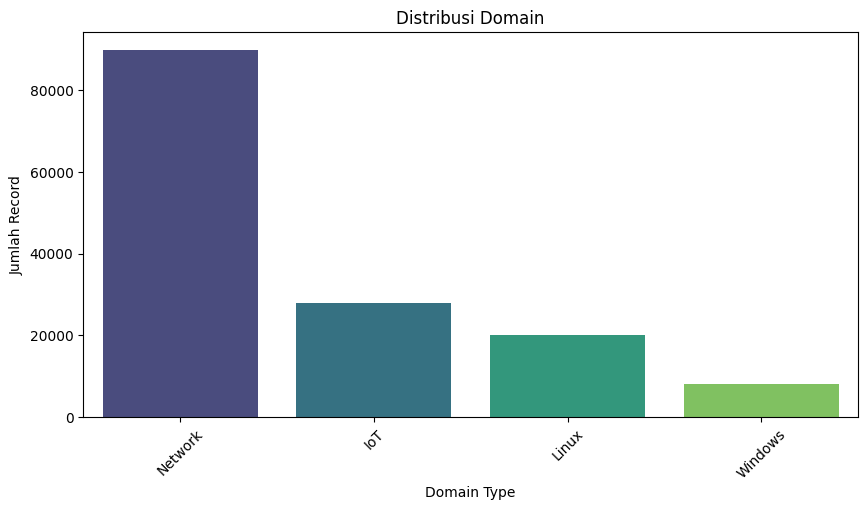

In [14]:
plt.figure(figsize=(10, 5))
domain_counts = pdf["Domain_Type"].value_counts()
sns.barplot(x=domain_counts.index, y=domain_counts.values, palette="viridis")
plt.title("Distribusi Domain")
plt.xlabel("Domain Type")
plt.ylabel("Jumlah Record")
plt.xticks(rotation=45)
plt.savefig("domain_distribution.png", dpi=150)
plt.show()

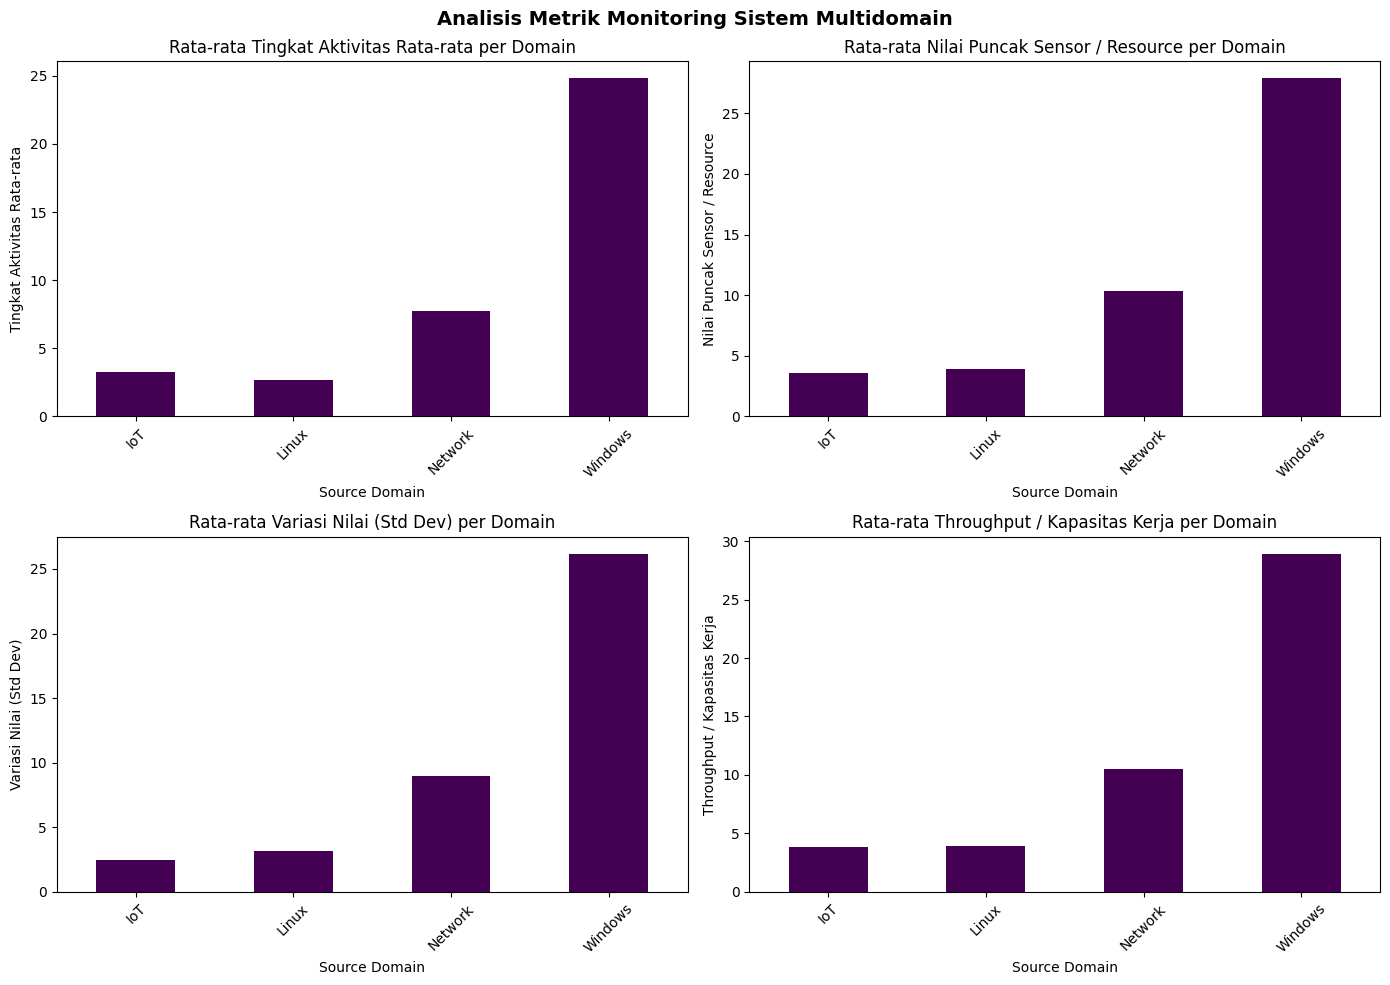

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = ["Metric_Activity", "Metric_Peak", "Metric_Variation", "Throughput_Metric"]
titles = ["Tingkat Aktivitas Rata-rata", "Nilai Puncak Sensor / Resource", "Variasi Nilai (Std Dev)", "Throughput / Kapasitas Kerja"]

for ax, metric, title in zip(axes.flatten(), metrics, titles):
    pdf.groupby("Source_Domain")[metric].mean().plot(kind="bar", ax=ax, colormap="viridis")
    ax.set_title(f"Rata-rata {title} per Domain")
    ax.set_xlabel("Source Domain")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Analisis Metrik Monitoring Sistem Multidomain", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("monitoring_analysis.png", dpi=150)
plt.show()

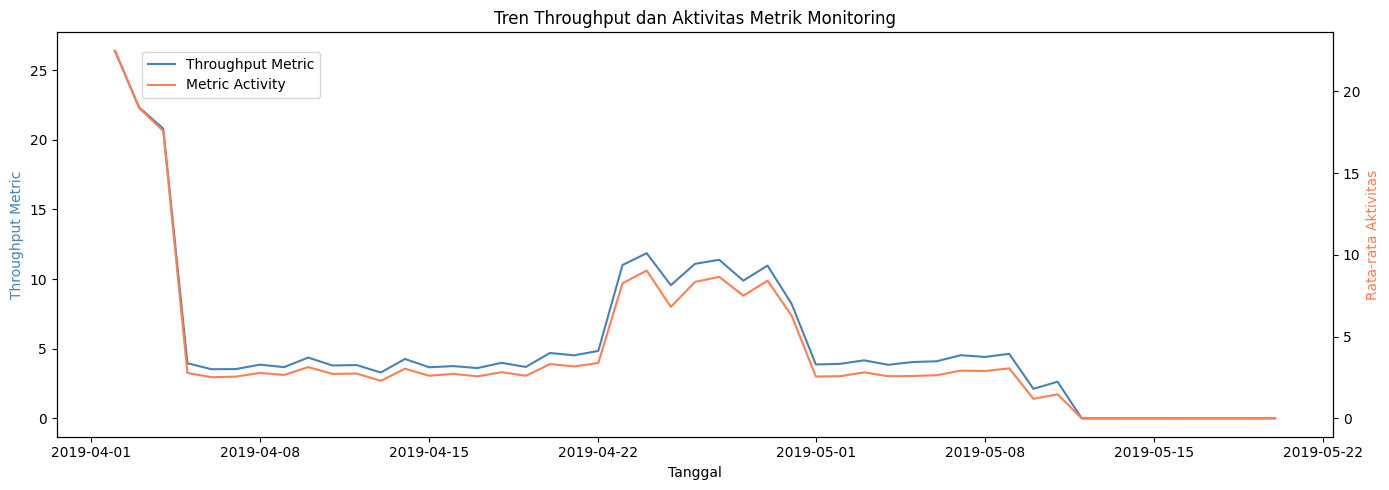

In [16]:
# Normalize mixed timestamp formats/time zones to one pandas datetime dtype.
pdf["Timestamp"] = pd.to_datetime(pdf["Timestamp"], errors="coerce", utc=True)
valid_time = pdf.dropna(subset=["Timestamp"]).copy()
if valid_time.empty:
    pdf_time = pd.DataFrame(columns=["Timestamp", "Throughput_Metric", "Metric_Activity"])
    print("Grafik tren dilewati: tidak ada Timestamp yang dapat diparse pada sample.")
else:
    valid_time["Timestamp"] = valid_time["Timestamp"].dt.floor("D")
    pdf_time = valid_time.groupby("Timestamp", as_index=False).agg({
        "Throughput_Metric": "mean",
        "Metric_Activity": "mean"
    })

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(pdf_time["Timestamp"], pdf_time["Throughput_Metric"], color="steelblue", label="Throughput Metric")
ax1.set_xlabel("Tanggal")
ax1.set_ylabel("Throughput Metric", color="steelblue")
ax2 = ax1.twinx()
ax2.plot(pdf_time["Timestamp"], pdf_time["Metric_Activity"], color="coral", label="Metric Activity")
ax2.set_ylabel("Rata-rata Aktivitas", color="coral")
plt.title("Tren Throughput dan Aktivitas Metrik Monitoring")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9))
plt.tight_layout()
plt.savefig("monitoring_trend.png", dpi=150)
plt.show()

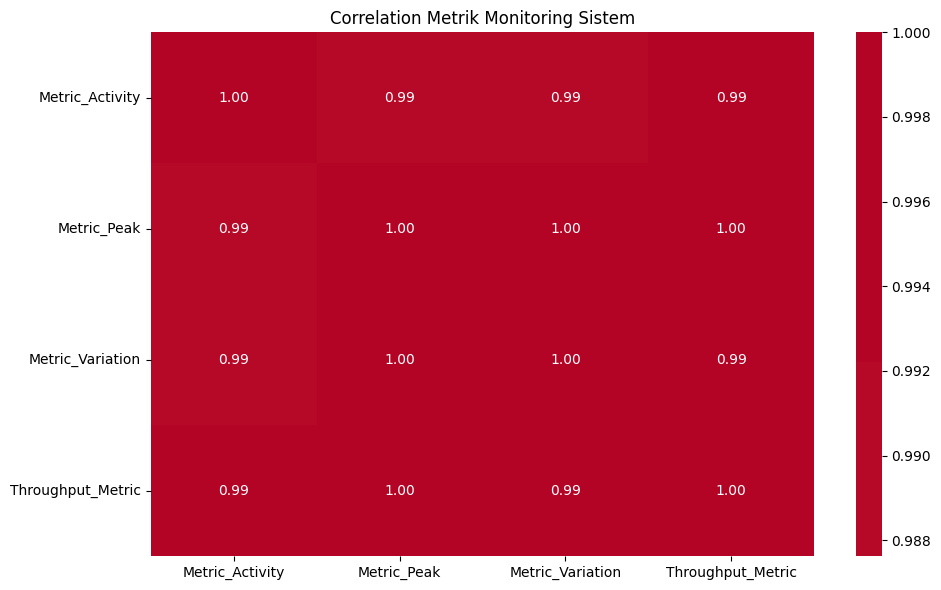

In [17]:
plt.figure(figsize=(10, 6))
numeric_cols = ["Metric_Activity", "Metric_Peak", "Metric_Variation", "Throughput_Metric"]
corr_matrix = pdf[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Metrik Monitoring Sistem")
plt.tight_layout()
plt.savefig("monitoring_correlation_heatmap.png", dpi=150)
plt.show()

In [18]:
target_cols = ["Target_Label", "Target_Type"]
AGGREGATE_FEATURE_COLS = [
    "Metric_Activity", "Metric_Peak", "Metric_Variation", "Throughput_Metric"
]
# Clustering eksploratif dan Multidomain memakai ruang fitur bersama.
# Klasifikasi domain heterogen memakai kolom numerik asli, bukan hanya agregat.
model_feature_cols = AGGREGATE_FEATURE_COLS
feature_cols = model_feature_cols
# Kolom num_*/cat_* milik domain lain bernilai nol di semua baris domain ini
# (konstruk union antar-file): dibuang agar RF/K-Means tidak memodelkan noise
# konstan. Batas varians > 0 dihitung dari sampel domain yang sama.
_all_sparse_cols = sorted(
    column for column in df.columns if column.startswith(("num_", "cat_", "code_"))
)
domain_feature_cols = {"Multidomain": list(AGGREGATE_FEATURE_COLS)}
for _domain in ["IoT", "Linux"]:
    _mask = pdf["Domain_Type"] == _domain
    _kept = [
        column for column in _all_sparse_cols
        if _mask.sum() > 0 and float(pdf.loc[_mask, column].fillna(0.0).std(ddof=0) or 0.0) > 0.0
    ]
    domain_feature_cols[_domain] = list(AGGREGATE_FEATURE_COLS) + _kept
for _domain in ["Network", "Windows"]:
    domain_feature_cols[_domain] = list(AGGREGATE_FEATURE_COLS)
print({domain: len(cols) for domain, cols in domain_feature_cols.items()})

pdf_ml = pdf.copy()
pdf_ml[feature_cols] = (
    pdf_ml[feature_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0.0)
)

print(f"Fitur model: {feature_cols}")
print(f"Total record sample model: {len(pdf_ml):,}")
print(f"Distribusi label: {pdf_ml['Target_Label'].value_counts().to_dict()}")

{'Multidomain': 4, 'IoT': 27, 'Linux': 31, 'Network': 4, 'Windows': 4}
Fitur model: ['Metric_Activity', 'Metric_Peak', 'Metric_Variation', 'Throughput_Metric']
Total record sample model: 145,786
Distribusi label: {1: 95309, 0: 50477}


In [19]:
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features_raw")
df_assembled = assembler.transform(df)

In [20]:
spark_scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withStd=True,
    withMean=True
)
spark_scaler_model = spark_scaler.fit(df_assembled)
df_scaled = spark_scaler_model.transform(df_assembled)

In [21]:
df_scaled.select("Record_ID", "features").show(5, truncate=False)

+-----------------+--------------------------------------------------------------------------------+
|Record_ID        |features                                                                        |
+-----------------+--------------------------------------------------------------------------------+
|IoT_Fridge_315908|[-1.5367758519034533,-1.7556592160933586,-2.051309955628269,-1.7905829014240633]|
|IoT_Fridge_178585|[-1.764924345807006,-1.9354877750270743,-2.051309955628269,-1.9692483091357582] |
|IoT_Fridge_62933 |[-1.3072421271473584,-1.5747388065682102,-2.051309955628269,-1.610832705332618] |
|IoT_Fridge_152596|[-1.3335587766020565,-1.5954818106811486,-2.051309955628269,-1.631441541376116] |
|IoT_Fridge_310734|[-1.764924345807006,-1.9354877750270743,-2.051309955628269,-1.9692483091357582] |
+-----------------+--------------------------------------------------------------------------------+
only showing top 5 rows



In [22]:
spark_training = (
    df_scaled
    .select("Record_ID", "features")
    .sample(False, 0.02, seed=RANDOM_STATE)
    .limit(300000)
    .cache()
)
spark_training_count = spark_training.count()
print(f"Data training K-Means Spark: {spark_training_count:,} baris")

inertia = []
k_values = range(2, 8)

for k in k_values:
    kmeans = KMeans(featuresCol="features", predictionCol="cluster", k=k, seed=RANDOM_STATE)
    model = kmeans.fit(spark_training)
    inertia.append(model.summary.trainingCost)
    print(f"K={k}, Inertia={model.summary.trainingCost:.4f}")

Data training K-Means Spark: 300,000 baris
K=2, Inertia=148648.9368
K=3, Inertia=61624.1410
K=4, Inertia=47623.0135
K=5, Inertia=36871.4089
K=6, Inertia=33198.7824
K=7, Inertia=22485.7384


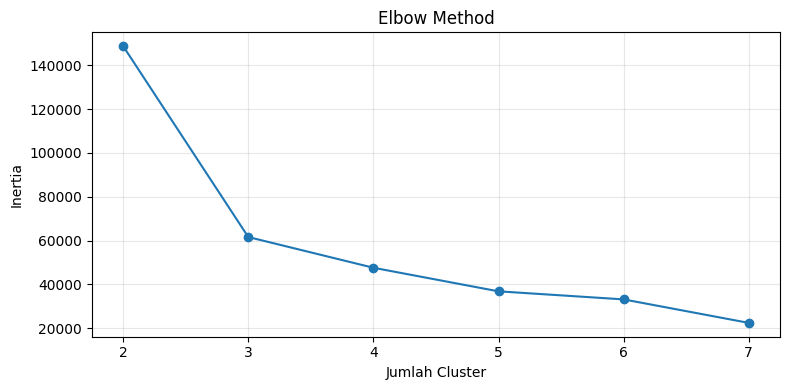

In [23]:
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertia, marker="o")
plt.xlabel("Jumlah Cluster")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("elbow_method.png", dpi=150)
plt.show()

In [24]:
# Silhouette-based K selection uses Spark MLlib on the Spark training sample.
evaluator = ClusteringEvaluator(
    featuresCol="features", predictionCol="cluster", metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)
spark_k_scores = {}
for candidate_k in range(2, 7):
    candidate_model = KMeans(
        featuresCol="features", predictionCol="cluster",
        k=candidate_k, seed=RANDOM_STATE
    ).fit(spark_training)
    candidate_predictions = candidate_model.transform(spark_training)
    try:
        spark_k_scores[candidate_k] = evaluator.evaluate(candidate_predictions)
    except Exception as error:
        print(f"Silhouette K={candidate_k} tidak dapat dihitung: {error}")

best_k = max(spark_k_scores, key=spark_k_scores.get) if spark_k_scores else 2
print(f"K terbaik menurut Spark MLlib Silhouette: {best_k}")
print(spark_k_scores)

K terbaik menurut Spark MLlib Silhouette: 2
{2: 0.9356869596002694, 3: 0.9162776433655323, 4: 0.8654114816925927, 5: 0.850035999329901, 6: 0.5812732870420244}


In [25]:
kmeans = KMeans(featuresCol="features", predictionCol="cluster", k=best_k, seed=RANDOM_STATE)
model = kmeans.fit(spark_training)
df_clustered = model.transform(df_scaled)

In [26]:
eval = ClusteringEvaluator(featuresCol="features", predictionCol="cluster")
silhouette_sample = (
    df_clustered
    .select("features", "cluster")
    .sample(False, 0.02, seed=RANDOM_STATE)
    .limit(100000)
)
silhouette = eval.evaluate(silhouette_sample)
print(f"Silhouette Score Spark Multidomain (sample): {silhouette:.4f}")

Silhouette Score Spark Multidomain (sample): 0.8545


In [27]:
df_clustered.groupBy("cluster").agg(
    F.count("*").alias("Jumlah"),
    F.round(F.avg("Metric_Activity"), 4).alias("Avg_Activity"),
    F.round(F.avg("Metric_Peak"), 4).alias("Avg_Peak"),
    F.round(F.avg("Metric_Variation"), 4).alias("Avg_Variation"),
    F.round(F.avg("Throughput_Metric"), 4).alias("Avg_Throughput")
).orderBy("cluster").show()

+-------+--------+------------+--------+-------------+--------------+
|cluster|  Jumlah|Avg_Activity|Avg_Peak|Avg_Variation|Avg_Throughput|
+-------+--------+------------+--------+-------------+--------------+
|      0| 7550012|      1.8349|  2.5733|       1.7329|         2.719|
|      1|22316596|       7.939| 10.4634|       9.1031|       10.6515|
+-------+--------+------------+--------+-------------+--------------+



In [28]:
eval = ClusteringEvaluator(featuresCol="features", predictionCol="cluster")
silhouette_sample = (
    df_clustered
    .select("features", "cluster")
    .sample(False, 0.02, seed=RANDOM_STATE)
    .limit(100000)
)
silhouette = eval.evaluate(silhouette_sample)
print(f"Silhouette Score Spark Multidomain (sample): {silhouette:.4f}")

Silhouette Score Spark Multidomain (sample): 0.8545


In [29]:
pdf_clustered = (
    df_clustered.select(
        "Domain_Type",
        "Metric_Activity",
        "Throughput_Metric",
        "cluster"
    )
    .sample(False, 0.01, seed=RANDOM_STATE)
    .limit(100000)
    .toPandas()
)

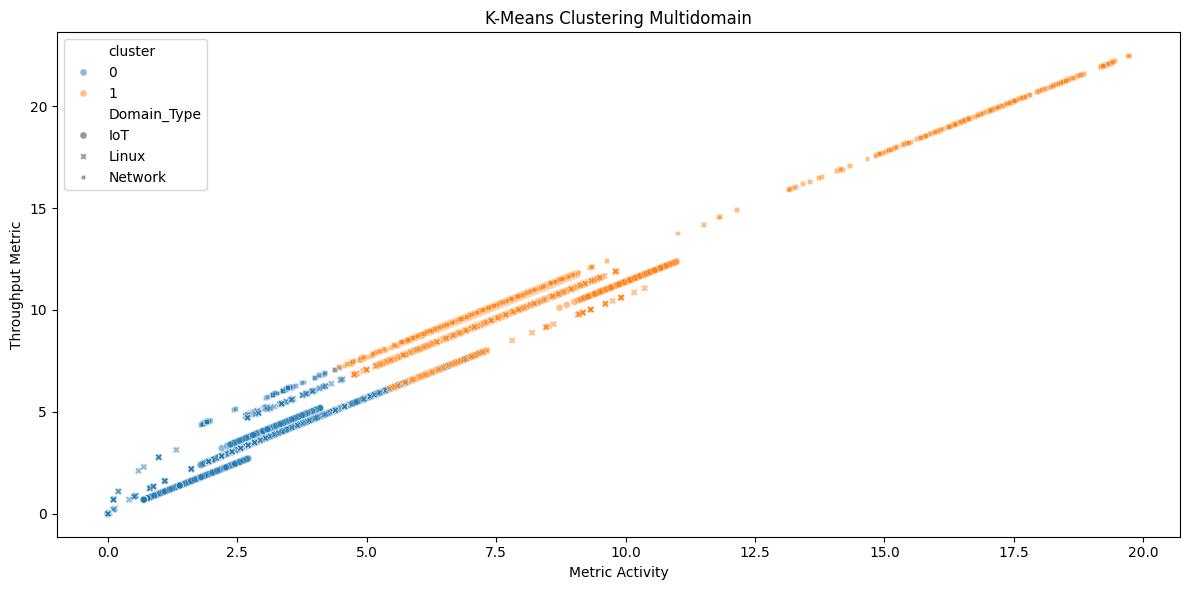

In [30]:
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=pdf_clustered,
    x="Metric_Activity",
    y="Throughput_Metric",
    hue="cluster",
    style="Domain_Type",
    alpha=0.5,
    s=25
)
plt.xlabel("Metric Activity")
plt.ylabel("Throughput Metric")
plt.title("K-Means Clustering Multidomain")
plt.tight_layout()
plt.savefig("kmeans_clustering.png", dpi=150)
plt.show()

In [31]:
cluster_summary = (
    pdf_clustered.groupby(["Domain_Type", "cluster"])
    .size()
    .reset_index(name="Records")
)
display(cluster_summary)
cluster_summary.to_csv("cluster_summary.csv", index=False)

,Domain_Type,cluster,Records
0,IoT,0,16404
1,IoT,1,1730
2,Linux,0,19427
3,Linux,1,5108
4,Network,0,697
5,Network,1,56634


In [32]:
graph_source = df.select(
    "Device_Type",
    "Source_File",
    "Source_Domain",
    "Domain_Type",
    "System_Region",
    "Metric_Activity",
    "Throughput_Metric",
    "Metric_Peak",
    "Metric_Variation",
)

graph_source = graph_source.filter(F.col("Source_Domain") != "Windows")  # ← tambah di sini

try:
    spark.conf.set("spark.sql.shuffle.partitions", "4")

    graph_rows = (
        graph_source
        .groupBy(
            "Device_Type",
            "Source_File",
            "Source_Domain",
            "Domain_Type",
            "System_Region",
        )
        .agg(
            F.avg("Metric_Activity").alias("Metric_Activity"),
            F.avg("Throughput_Metric").alias("Throughput_Metric"),
            F.avg("Metric_Peak").alias("Metric_Peak"),
            F.avg("Metric_Variation").alias("Metric_Variation"),
        )
        .collect()
    )

    pdf_graph = pd.DataFrame([row.asDict() for row in graph_rows])
    print(f"Berhasil membuat ringkasan grafik: {len(pdf_graph):,} baris")

except Exception as e:
    print(f"Gagal membuat ringkasan grafik: {type(e).__name__}: {e}")
    raise

Berhasil membuat ringkasan grafik: 35 baris


In [33]:
if not driver:
    print("Neo4j tidak terhubung, ingest dilewati.")
else:
    with driver.session() as session:
        session.run("MATCH (n) DETACH DELETE n")
        session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (d:Device) REQUIRE d.name IS UNIQUE")
        session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (r:Region) REQUIRE r.name IS UNIQUE")
        session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (dom:Domain) REQUIRE dom.name IS UNIQUE")
    print("Database dibersihkan & constraint dibuat.")

Database dibersihkan & constraint dibuat.


In [34]:
device = pdf_graph.groupby(["Device_Type", "System_Region"]).agg(
    weight=("Throughput_Metric", "mean"),
    activity=("Metric_Activity", "mean"),
    peak=("Metric_Peak", "mean"),
    records=("Throughput_Metric", "count")
).reset_index()

domain = pdf_graph.groupby(["System_Region", "Domain_Type"]).agg(
    weight=("Throughput_Metric", "mean"),
    activity=("Metric_Activity", "mean"),
    records=("Throughput_Metric", "count")
).reset_index()

In [35]:
try:
    for _, row in device.iterrows():
        cypher = """
        MERGE (d:Device {name: $device})
        MERGE (r:Region {name: $region})
        MERGE (d)-[rel:ROUTES_TO]->(r)
        SET rel.weight = $weight, rel.activity = $activity
        """
        run_query(cypher, {
            "device": str(row["Device_Type"]),
            "region": str(row["System_Region"]),
            "weight": float(round(row["weight"], 2)),
            "activity": float(round(row["activity"], 2))
        })
    print("Data Device berhasil diunggah ke Neo4j.")
except Exception as error:
    print(f"Neo4j offline saat upload device: {error}")

Data Device berhasil diunggah ke Neo4j.


In [36]:
try:
    for _, row in domain.iterrows():
        cypher = """
        MERGE (r:Region {name: $region})
        MERGE (dom:Domain {name: $domain})
        MERGE (r)-[rel:SERVES]->(dom)
        SET rel.weight = $weight, rel.activity = $activity
        """
        run_query(cypher, {
            "region": str(row["System_Region"]),
            "domain": str(row["Domain_Type"]),
            "weight": float(round(row["weight"], 2)),
            "activity": float(round(row["activity"], 2))
        })
    print("Data Region dan Domain berhasil diunggah ke Neo4j.")
except Exception as error:
    print(f"Neo4j offline saat upload domain: {error}")

Data Region dan Domain berhasil diunggah ke Neo4j.


In [37]:
try:
    count_nodes = run_query("MATCH (n) RETURN count(n) AS total_nodes")[0]["total_nodes"]
    count_edges = run_query("MATCH ()-[r]->() RETURN count(r) AS total_edges")[0]["total_edges"]
except Exception as error:
    print(f"Neo4j offline saat verifikasi: {error}")
    count_nodes, count_edges = 0, 0

In [38]:
print("Nodes di Neo4j -> ", count_nodes)
print("Edges di Neo4j -> ", count_edges)

Nodes di Neo4j ->  41
Edges di Neo4j ->  38


In [39]:
degree_query = """
MATCH (n)
OPTIONAL MATCH (n)-[r]-()
RETURN n.name AS node, count(r) * 1.0 AS degree
ORDER BY degree DESC
"""
try:
    degree_res = run_query(degree_query)
    max_deg = (count_nodes - 1) if count_nodes > 1 else 1.0
    degree_cent = {r["node"]: r["degree"] / max_deg for r in degree_res if r.get("node")}
    if not degree_cent:
        raise ValueError("Hasil degree query kosong")
except Exception:
    G_temp = nx.DiGraph()
    for _, r in device.iterrows():
        G_temp.add_edge(r["Device_Type"], r["System_Region"], weight=r["weight"])
    for _, r in domain.iterrows():
        G_temp.add_edge(r["System_Region"], r["Domain_Type"], weight=r["weight"])
    degree_cent = nx.degree_centrality(G_temp)

In [40]:
betweenness_cent = {}
pagerank = {}

try:
    run_query("""
    CALL gds.graph.project.cypher(
        'iotGraph',
        'MATCH (n) RETURN id(n) AS id, labels(n) AS labels',
        'MATCH (s)-[r]->(t) RETURN id(s) AS source, id(t) AS target, type(r) AS type, r.weight AS weight'
    )
    """)

    pr_records = run_query("CALL gds.pageRank.stream('iotGraph') YIELD nodeId, score RETURN gds.util.asNode(nodeId).name AS node, score")
    pagerank = {r["node"]: r["score"] for r in pr_records if r.get("node")}
    
    bw_records = run_query("CALL gds.betweenness.stream('iotGraph') YIELD nodeId, score RETURN gds.util.asNode(nodeId).name AS node, score")
    betweenness_cent = {r["node"]: r["score"] for r in bw_records if r.get("node")}
    if not (betweenness_cent and pagerank):
        raise ValueError("Hasil GDS kosong")
    print("Graph Analytics berhasil dihitung menggunakan Neo4j GDS Plugin!")
except Exception:
    G_net = nx.DiGraph()
    try:
        edges_data = run_query("MATCH (a)-[r]->(b) RETURN a.name AS source, b.name AS target, r.weight AS weight")
    except Exception:
        edges_data = []

    if edges_data:
        for edge in edges_data:
            G_net.add_edge(edge["source"], edge["target"], weight=edge.get("weight", 1.0))
    else:
        for _, r in device.iterrows():
            G_net.add_edge(r["Device_Type"], r["System_Region"], weight=r["weight"])
        for _, r in domain.iterrows():
            G_net.add_edge(r["System_Region"], r["Domain_Type"], weight=r["weight"])

    betweenness_cent = nx.betweenness_centrality(G_net)
    pagerank = nx.pagerank(G_net, weight="weight")
    if not degree_cent:
        degree_cent = nx.degree_centrality(G_net)
    print("Graph Analytics berhasil dihitung menggunakan NetworkX fallback!")

Graph Analytics berhasil dihitung menggunakan NetworkX fallback!


In [41]:
for node, score in sorted(degree_cent.items(), key=lambda x: x[1], reverse=True):
    print(f"{node}: {score:.4f}")

Network_Gateway_Core: 0.6000
IoT_Smart_Environment: 0.2000
Linux_Host_Cluster: 0.1500
IoT_Weather: 0.0250
Linux_process_1: 0.0250
Linux_process_2: 0.0250
Network_dataset_1: 0.0250
Network_dataset_10: 0.0250
Network_dataset_11: 0.0250
Network_dataset_12: 0.0250
Network_dataset_13: 0.0250
Network_dataset_14: 0.0250
Network_dataset_15: 0.0250
Network_dataset_16: 0.0250
Network_dataset_17: 0.0250
Network_dataset_18: 0.0250
Network_dataset_19: 0.0250
Network_dataset_2: 0.0250
Network_dataset_20: 0.0250
Network_dataset_21: 0.0250
Network_dataset_22: 0.0250
Network_dataset_23: 0.0250
Network_dataset_3: 0.0250
Network_dataset_4: 0.0250
Network_dataset_5: 0.0250
Network_dataset_6: 0.0250
Network_dataset_7: 0.0250
Network_dataset_8: 0.0250
Network_dataset_9: 0.0250
linux_disk_2: 0.0250
linux_memory1: 0.0250
linux_memory2: 0.0250
IoT: 0.0250
Linux: 0.0250
Network: 0.0250
IoT_Fridge: 0.0250
IoT_GPS_Tracker: 0.0250
IoT_Garage_Door: 0.0250
IoT_Modbus: 0.0250
IoT_Motion_Light: 0.0250
IoT_Thermostat: 

In [42]:
for node, score in sorted(betweenness_cent.items(), key=lambda x: x[1], reverse=True):
    print(f"{node}: {score:.4f}")

Network_Gateway_Core: 0.0147
IoT_Smart_Environment: 0.0045
Linux_Host_Cluster: 0.0032
Network_dataset_1: 0.0000
Network_dataset_10: 0.0000
Network_dataset_11: 0.0000
Network_dataset_12: 0.0000
Network_dataset_13: 0.0000
Network_dataset_14: 0.0000
Network_dataset_15: 0.0000
Network_dataset_16: 0.0000
Network_dataset_17: 0.0000
Network_dataset_18: 0.0000
Network_dataset_19: 0.0000
Network_dataset_2: 0.0000
Network_dataset_20: 0.0000
Network_dataset_21: 0.0000
Network_dataset_22: 0.0000
Network_dataset_23: 0.0000
Network_dataset_3: 0.0000
Network_dataset_4: 0.0000
Network_dataset_5: 0.0000
Network_dataset_6: 0.0000
Network_dataset_7: 0.0000
Network_dataset_8: 0.0000
Network_dataset_9: 0.0000
linux_disk_2: 0.0000
linux_memory1: 0.0000
linux_memory2: 0.0000
IoT: 0.0000
Linux: 0.0000
Network: 0.0000
IoT_Fridge: 0.0000
IoT_GPS_Tracker: 0.0000
IoT_Garage_Door: 0.0000
IoT_Modbus: 0.0000
IoT_Motion_Light: 0.0000
IoT_Thermostat: 0.0000
IoT_Weather: 0.0000
Linux_process_1: 0.0000
Linux_process_2: 

In [43]:
for node, score in sorted(pagerank.items(), key=lambda x: x[1], reverse=True):
    print(f"{node}: {score:.4f}")

Network_Gateway_Core: 0.2118
Network: 0.1904
IoT: 0.0638
IoT_Smart_Environment: 0.0629
Linux: 0.0563
Linux_Host_Cluster: 0.0541
Network_dataset_1: 0.0103
Network_dataset_10: 0.0103
Network_dataset_11: 0.0103
Network_dataset_12: 0.0103
Network_dataset_13: 0.0103
Network_dataset_14: 0.0103
Network_dataset_15: 0.0103
Network_dataset_16: 0.0103
Network_dataset_17: 0.0103
Network_dataset_18: 0.0103
Network_dataset_19: 0.0103
Network_dataset_2: 0.0103
Network_dataset_20: 0.0103
Network_dataset_21: 0.0103
Network_dataset_22: 0.0103
Network_dataset_23: 0.0103
Network_dataset_3: 0.0103
Network_dataset_4: 0.0103
Network_dataset_5: 0.0103
Network_dataset_6: 0.0103
Network_dataset_7: 0.0103
Network_dataset_8: 0.0103
Network_dataset_9: 0.0103
linux_disk_2: 0.0103
linux_memory1: 0.0103
linux_memory2: 0.0103
IoT_Fridge: 0.0103
IoT_GPS_Tracker: 0.0103
IoT_Garage_Door: 0.0103
IoT_Modbus: 0.0103
IoT_Motion_Light: 0.0103
IoT_Thermostat: 0.0103
IoT_Weather: 0.0103
Linux_process_1: 0.0103
Linux_process_2: 

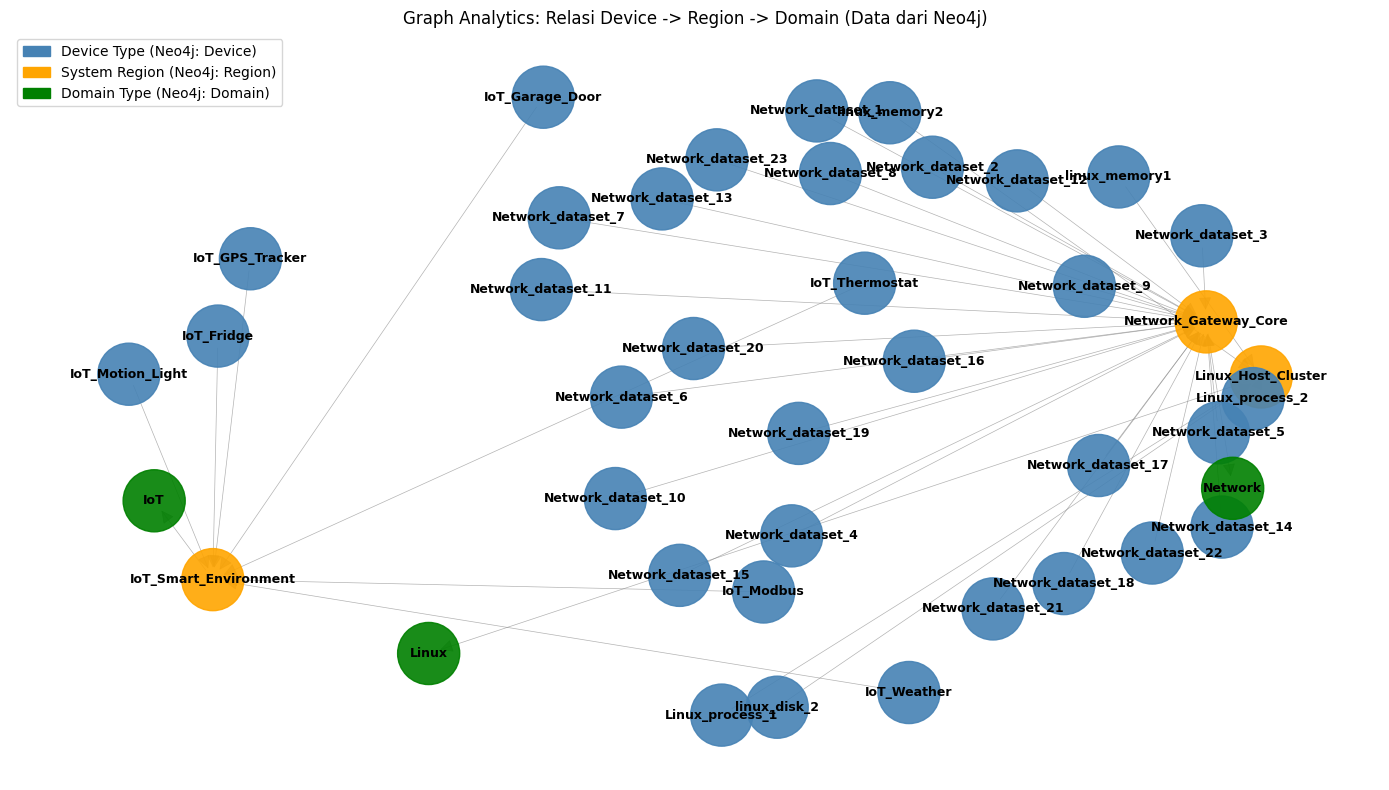

In [44]:
import networkx as nx
from matplotlib.patches import Patch

try:
    edges_data = run_query("""
    MATCH (a)-[r]->(b)
    RETURN a.name AS source, labels(a)[0] AS source_label, 
           b.name AS target, labels(b)[0] AS target_label, 
           r.weight AS weight
    """)
except Exception:
    edges_data = []

G = nx.DiGraph()
if edges_data:
    for edge in edges_data:
        G.add_edge(edge["source"], edge["target"], weight=edge["weight"])
else:
    for _, r in device.iterrows():
        G.add_edge(r["Device_Type"], r["System_Region"], weight=r["weight"])
    for _, r in domain.iterrows():
        G.add_edge(r["System_Region"], r["Domain_Type"], weight=r["weight"])

plt.figure(figsize=(14, 8))
color_map = []
for node in G.nodes():
    if node in pdf_graph["Device_Type"].values:
        color_map.append("steelblue")
    elif node in pdf_graph["System_Region"].values:
        color_map.append("orange")
    else:
        color_map.append("green")

pos = nx.spring_layout(G, seed=42, k=2)
weights = [max(0.5, G[u][v].get("weight", 1.0) / 100) for u, v in G.edges()]
nx.draw_networkx_nodes(G, pos, node_color=color_map, node_size=2000, alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")
nx.draw_networkx_edges(G, pos, width=weights, alpha=0.6, arrows=True, arrowsize=20, edge_color="gray")
legend = [
    Patch(color="steelblue", label="Device Type (Neo4j: Device)"),
    Patch(color="orange", label="System Region (Neo4j: Region)"),
    Patch(color="green", label="Domain Type (Neo4j: Domain)")
]
plt.legend(handles=legend, loc="upper left")
plt.title("Graph Analytics: Relasi Device -> Region -> Domain (Data dari Neo4j)")
plt.axis("off")
plt.tight_layout()
plt.savefig("graph_analytics.png", dpi=150)
plt.show()

In [45]:
if not betweenness_cent:
    G_fallback = nx.DiGraph()
    for _, r in device.iterrows():
        G_fallback.add_edge(r["Device_Type"], r["System_Region"], weight=r["weight"])
    for _, r in domain.iterrows():
        G_fallback.add_edge(r["System_Region"], r["Domain_Type"], weight=r["weight"])
    betweenness_cent = nx.betweenness_centrality(G_fallback)
    pagerank = nx.pagerank(G_fallback, weight="weight")

top_node = max(betweenness_cent, key=betweenness_cent.get)
print(f"Node paling kritis (Jalur Penghubung Utama): {top_node}")
print(f"Betweenness Centrality: {betweenness_cent[top_node]:.4f}")
print(f"PageRank: {pagerank[top_node]:.4f}")

Node paling kritis (Jalur Penghubung Utama): Network_Gateway_Core
Betweenness Centrality: 0.0147
PageRank: 0.2118


In [46]:
nodes_union = list(set(list(degree_cent.keys()) + list(betweenness_cent.keys()) + list(pagerank.keys())))
cent_df = pd.DataFrame({
    "Node": nodes_union,
    "Degree": [degree_cent.get(k, 0.0) for k in nodes_union],
    "Betweenness": [betweenness_cent.get(k, 0.0) for k in nodes_union],
    "PageRank": [pagerank.get(k, 0.0) for k in nodes_union]
}).sort_values("Betweenness", ascending=False)
cent_df.head(10)

,Node,Degree,Betweenness,PageRank
13,Network_Gateway_Core,0.600,0.014744,0.211818
33,IoT_Smart_Environment,0.200,0.004487,0.062876
32,Linux_Host_Cluster,0.150,0.003205,0.054114
1,Network_dataset_22,0.025,0.000000,0.010308
4,Network_dataset_12,0.025,0.000000,0.010308
5,Network,0.025,0.000000,0.190355
2,IoT_Garage_Door,0.025,0.000000,0.010308
3,Network_dataset_10,0.025,0.000000,0.010308
0,linux_memory2,0.025,0.000000,0.010308
8,Network_dataset_7,0.025,0.000000,0.010308


C:\Users\jase0\AppData\Local\Temp\ipykernel_4304\575621910.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x="Node", y=metric, palette="viridis", ax=ax)
C:\Users\jase0\AppData\Local\Temp\ipykernel_4304\575621910.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x="Node", y=metric, palette="viridis", ax=ax)
C:\Users\jase0\AppData\Local\Temp\ipykernel_4304\575621910.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x="Node", y=metric, palette="viridis", ax=ax)


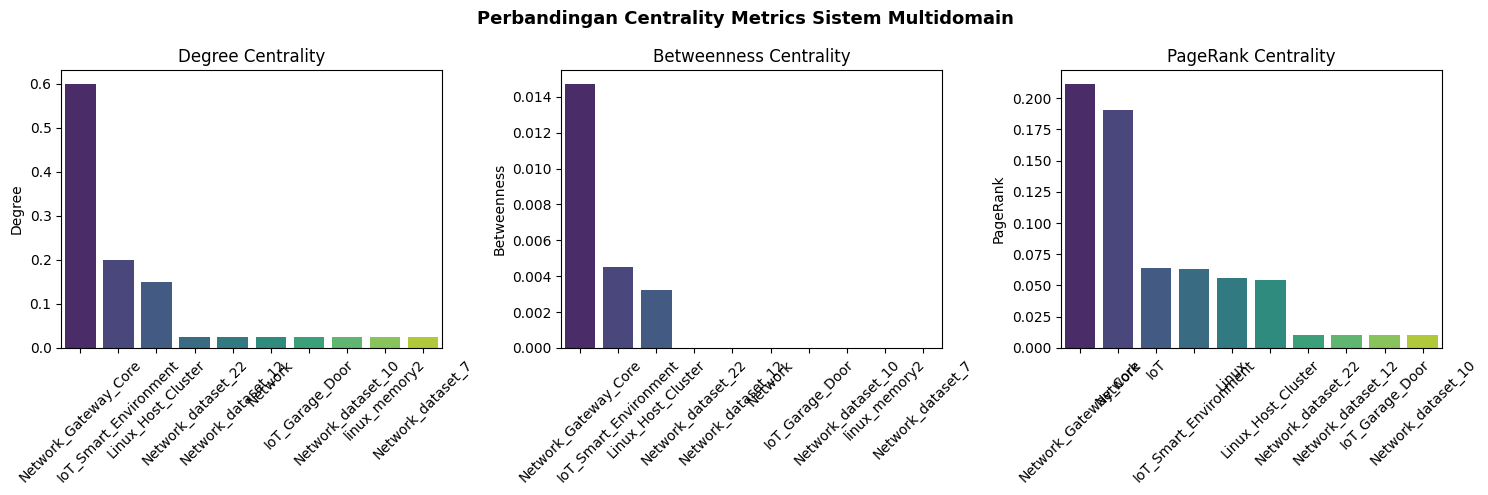

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = ["Degree", "Betweenness", "PageRank"]

for ax, metric in zip(axes, metrics):
    top10 = cent_df.nlargest(10, metric)
    sns.barplot(data=top10, x="Node", y=metric, palette="viridis", ax=ax)
    ax.set_title(f"{metric} Centrality")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Perbandingan Centrality Metrics Sistem Multidomain", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("centrality_analysis.png", dpi=150)
plt.show()

In [48]:
from pyspark.ml.feature import VectorAssembler, StandardScaler, StringIndexer, IndexToString
from pyspark.ml.clustering import KMeans
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F
from sklearn.ensemble import IsolationForest, RandomForestClassifier as SklearnRandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler as SklearnStandardScaler
from sklearn.cluster import KMeans as SklearnKMeans
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score, confusion_matrix
)
import random
import joblib
import shutil

import numpy as np


def _best_f1_threshold(y_true, scores):
    """Pilih cutoff F1 pada skor validasi/kalibrasi, bukan pada data test.

    Dipakai oleh RF (skor OOF/holdout train), K-Means, dan Isolation Forest.
    Kandidat mencakup 0.5, minimum skor (fallback prediksi semua positif),
    serta kuantil skor; label test tidak pernah dipakai
    untuk memilih cutoff. F1 adalah metrik optimasi kelas positif pada tugas ini.
    """
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    if len(scores) == 0 or len(np.unique(y_true)) < 2:
        return 0.5
    candidates = np.unique(np.concatenate([
        np.array([0.5, np.min(scores)]),
        np.quantile(scores, np.linspace(0.01, 0.99, 99)),
    ]))
    best_t, best_f1 = 0.5, -1.0
    for threshold in candidates:
        pred = (scores >= threshold).astype(int)
        tp = int(np.sum((pred == 1) & (y_true == 1)))
        fp = int(np.sum((pred == 1) & (y_true == 0)))
        fn = int(np.sum((pred == 0) & (y_true == 1)))
        denom = 2 * tp + fp + fn
        f1 = (2.0 * tp / denom) if denom else 0.0
        if f1 > best_f1:
            best_t, best_f1 = float(threshold), f1
    return best_t


from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold


def _make_sklearn_rf(max_depth=12):
    """RF scikit-learn biner: parameter dipusatkan agar kalibrasi OOF memakai
    konfigurasi yang sama persis dengan model final. IoT/Linux memakai
    max_depth=18 (ruang fitur gabungan antar-file butuh routing per-sumber
    sebelum split diskriminatif; train ~10-13rb baris sehingga depth 18 aman)."""
    return SklearnRandomForestClassifier(
        n_estimators=MODEL_N_ESTIMATORS, min_samples_leaf=2, max_depth=max_depth,
        class_weight="balanced_subsample", random_state=MODEL_RANDOM_STATE, n_jobs=-1
    )


def _oof_scores(estimator, X, y, n_splits=5):
    """Probabilitas out-of-fold kelas positif (StratifiedKFold).

    Skor in-sample RF overconfident karena memorization: threshold yang "pas"
    di train tidak transfer ke test (kasus IoT: seluruh skor test di bawah
    cutoff hasil train -> nol deteksi). Skor OOF dihitung oleh model yang tidak
    pernah melihat baris bersangkutan sehingga distribusinya realistis.
    """
    y = np.asarray(y).astype(int)
    scores = np.zeros(len(y), dtype=float)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=MODEL_RANDOM_STATE)
    for fit_idx, val_idx in skf.split(X, y):
        fold_model = clone(estimator).fit(X[fit_idx], y[fit_idx])
        fold_classes = list(fold_model.classes_)
        if 1 in fold_classes:
            scores[val_idx] = fold_model.predict_proba(X[val_idx])[:, fold_classes.index(1)]
    return scores


def _best_balanced_accuracy_threshold(y_true, scores):
    """Threshold skor yang memaksimalkan balanced accuracy pada skor kalibrasi
    (out-of-fold atau validasi holdout dari train).

    Balanced accuracy = (recall + specificity) / 2 sehingga tidak bergantung pada
    prevalensi anomali. Kriteria F1 mudah bias saat prevalensi train != test:
    IoT (train didominasi satu kelas) menghasilkan cutoff yang menghapus semua
    prediksi anomali di test (F1 = 0), sementara Network memprediksi ~100% baris
    sebagai anomali (balanced accuracy ~0.52). Kandidat dengan balanced accuracy
    nyaris sama (selisih <= 1e-3) di-tie-break memakai F1 tertinggi agar
    precision tidak dikorbankan tanpa alasan. 0.5 tetap jadi kandidat, jadi bila
    default memang terbaik di train, perilaku tidak berubah.
    """
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    if len(scores) == 0 or len(np.unique(y_true)) < 2:
        return 0.5
    candidates = np.unique(np.concatenate([
        np.array([0.5, np.min(scores)]),
        np.quantile(scores, np.linspace(0.01, 0.99, 99)),
    ]))
    evaluated = []
    for threshold in candidates:
        pred = (scores >= threshold).astype(int)
        tp = int(np.sum((pred == 1) & (y_true == 1)))
        fp = int(np.sum((pred == 1) & (y_true == 0)))
        fn = int(np.sum((pred == 0) & (y_true == 1)))
        tn = int(np.sum((pred == 0) & (y_true == 0)))
        recall = tp / (tp + fn) if tp + fn else 0.0
        specificity = tn / (tn + fp) if tn + fp else 0.0
        balanced = (recall + specificity) / 2.0
        denom = 2 * tp + fp + fn
        f1 = (2.0 * tp / denom) if denom else 0.0
        evaluated.append((balanced, f1, float(threshold)))
    best_balanced = max(item[0] for item in evaluated)
    near_best = [item for item in evaluated if best_balanced - item[0] <= 1e-3]
    return max(near_best, key=lambda item: (item[1], item[0]))[2]

MODEL_TEST_SIZE = 0.2
MODEL_RANDOM_STATE = 42
MODEL_N_ESTIMATORS = 200
MODEL_ANOMALY_QUANTILE = 0.95
MODEL_MAX_TRAIN_ROWS = 300000
# Di bawah jumlah baris train ini, validasi holdout/OOF terlalu kecil
# sehingga threshold kalibrasinya tidak stabil (kasus Windows: 199 baris
# train -> threshold 0.017, over-prediksi anomali 71%). Kalibrasi kembali
# ke skor in-sample untuk domain sekecil ini.
MODEL_MIN_CALIB_ROWS = 2000
# Selisih maksimum proporsi anomali train vs test agar susunan file test langsung
# diterima. Mencegah split ekstrem (kasus IoT: train ~94% anomali vs test 16%)
# yang membuat classifier tidak bisa generalisasi.
SPLIT_PREVALENCE_TOLERANCE = 0.05

In [49]:
def _safe_binary_metrics(scored_df, label_col="Target_Label", prediction_col="prediction", score_col="positive_score"):
    row = scored_df.agg(
        F.sum(F.when((F.col(label_col) == 1) & (F.col(prediction_col) == 1), 1).otherwise(0)).alias("tp"),
        F.sum(F.when((F.col(label_col) == 0) & (F.col(prediction_col) == 0), 1).otherwise(0)).alias("tn"),
        F.sum(F.when((F.col(label_col) == 0) & (F.col(prediction_col) == 1), 1).otherwise(0)).alias("fp"),
        F.sum(F.when((F.col(label_col) == 1) & (F.col(prediction_col) == 0), 1).otherwise(0)).alias("fn"),
        F.count(F.lit(1)).alias("n")
    ).first()
    tp, tn, fp, fn, n = [int(row[k] or 0) for k in ("tp", "tn", "fp", "fn", "n")]
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    metrics = {
        "Accuracy": (tp + tn) / n if n else 0.0,
        "Balanced_Accuracy": (recall + specificity) / 2 if n else 0.0,
        "Precision": precision, "Recall": recall, "F1": f1,
        "Average_Precision": np.nan,
        "_confusion": [[tn, fp], [fn, tp]],
        "_positive_rate": (tp + fn) / n if n else 0.0,
        "_predicted_positive_rate": (tp + fp) / n if n else 0.0,
        "_count": n
    }
    if tp + fn > 0 and tn + fp > 0 and "probability" in scored_df.columns:
        try:
            metrics["Average_Precision"] = float(BinaryClassificationEvaluator(
                labelCol=label_col, rawPredictionCol="probability", metricName="areaUnderPR"
            ).evaluate(scored_df))
        except Exception as error:
            print(f"Average precision dilewati: {error}")
    return metrics


def _distinct_labels(df):
    return {str(r[0]) for r in df.select("Target_Label").distinct().collect()}


def _split_spark_by_domain(data, domain_name):
    """Stratified row split per baris memakai kolom stratum gabungan.

    Pengganti file-level holdout untuk IoT/Linux: kolom `num_*` tiap sumber
    punya arti fisis berbeda (mis. kolom suhu di satu file = kolom kelembapan
    di file lain), sehingga model yang diuji pada file yang belum terlihat
    dipaksa menebak pemetaan sensor baru -> F1 kolaps (IoT ~0.13, Linux
    ~0.19). Split acak berstrata (label x file) membuat train/test mencakup
    semua sensor/sumber dengan proporsi yang sama, jadi angka yang dilaporkan
    = performa deteksi pada perangkat yang dipantau, bukan generalisasi
    zero-shot ke tipe sensor baru (itu tetap diukur cell temporal per-source
    di bawah). Multidomain/Network/Windows memakai fungsi yang sama agar
    metodologi konsisten; label split menjadi
    "stratified source-aware row split".
    """
    label_col, file_col = "Target_Label", "Source_File"
    counts = data.groupBy(file_col, label_col).count().collect()
    per_file_labels = {}
    for row in counts:
        if row[file_col] is None:
            continue
        per_file_labels.setdefault(row[file_col], set()).add(int(row[label_col]))
    # File single-class dibiarkan: stratum file x label tetap membagi barisnya
    # ke train/test; yang wajib dua kelas adalah gabungan train dan test
    # (dicek di bawah), bukan tiap file.
    # Stratified 80/20 per stratum dalam SATU pass: row_number() acak di dalam
    # tiap stratum, tiap baris ke-`folds` -> test. Versi loop-union per stratum
    # sebelumnya membuat lineage plan sedalam jumlah stratum (puluhan union +
    # randomSplit) sehingga tiap .count()/.collect() meledak -> Java heap OOM.
    # Bentuk ini semurah plan lama (withColumn + 2 filter).
    from pyspark.sql import Window as _SplitWindow
    _folds = max(2, int(round(1.0 / MODEL_TEST_SIZE)))
    keyed = data.withColumn("_stratum", F.concat_ws("::", F.col(file_col), F.col(label_col).cast("string")))
    keyed = keyed.withColumn("_rand", F.rand(MODEL_RANDOM_STATE)).withColumn(
        "_rn",
        F.row_number().over(_SplitWindow.partitionBy("_stratum").orderBy(F.col("_rand"))),
    )
    train = keyed.where((F.col("_rn") % _folds) != 0).drop("_stratum", "_rand", "_rn")
    test = keyed.where((F.col("_rn") % _folds) == 0).drop("_stratum", "_rand", "_rn")
    if not (train.limit(1).count() and test.limit(1).count()):
        raise ValueError(f"{domain_name}: split menghasilkan data train/test tidak cukup.")
    train_labels = {int(r["Target_Label"]) for r in train.select("Target_Label").distinct().collect()}
    test_labels = {int(r["Target_Label"]) for r in test.select("Target_Label").distinct().collect()}
    if len(train_labels) < 2 or len(test_labels) < 2:
        raise ValueError(f"{domain_name}: split berstrata gagal memuat dua kelas di train/test.")
    return train, test, "stratified source-aware row split"


def _with_squared_centroid_distance(scored, kmeans_model, features_col="scaled_features"):
    centers = kmeans_model.clusterCenters()
    centers_expr = F.array(*[
        F.array(*[F.lit(float(value)) for value in center.tolist()])
        for center in centers
    ])
    nearest_center = F.element_at(centers_expr, F.col("cluster") + F.lit(1))
    differences = F.zip_with(vector_to_array(F.col(features_col)), nearest_center, lambda x, y: (x - y) * (x - y))
    return scored.withColumn("anomaly_score", F.aggregate(differences, F.lit(0.0), lambda acc, value: acc + value))


# ---------------------------------------------------------------------------
# Fitur temporal kausal (per Source_File)
# ---------------------------------------------------------------------------
# Model berbasis satu baris tidak bisa membedakan serangan yang hanya terlihat
# dari perubahan antar-detik (IoT) atau dari lonjakan relatif terhadap kondisi
# normal proses (Linux). Statistik jendela di bawah hanya memakai baris yang
# LEBIH AWAL (rowsBetween(-w, -1)) sehingga tidak ada kebocoran label/nilai dari
# baris itu sendiri maupun baris setelahnya.
TEMPORAL_ROLL_WINDOW = int(os.getenv("TEMPORAL_ROLL_WINDOW", "30"))
TEMPORAL_CHUNK_SIZE = 24
TEMPORAL_SCALAR_COLS = ["dt", "dt_zero", "hour", "minute", "second"]


def _parse_event_time(frame):
    """`Timestamp` -> timestamp yang bisa diparse untuk keempat domain.

    IoT menulis `date` + `time`; sebagian `time` hanya jam, sebagian sudah
    datetime penuh, sehingga concat bisa menjadi `2-Apr-19 2026-11-06 04:05:35`.
    Token pertama = tanggal, token terakhir = jam; Linux/Network/Windows sudah
    `yyyy-MM-dd HH:mm:ss`. Hasilnya epoch detik (double) agar `lag`/window
    konsisten antar-domain.
    """
    tokens = F.split(F.trim(F.col("Timestamp")), r"\s+")
    date_part = F.element_at(tokens, 1)
    time_part = F.element_at(tokens, -1)
    joined = F.concat_ws(" ", date_part, time_part)
    parsed = F.coalesce(
        # Jam satu digit (`3-Apr-19 1:18:20`) tidak cocok dengan `HH`; `H`
        # menerima kedua bentuk tanpa perlu normalisasi di dataset builder.
        F.to_timestamp(joined, "d-MMM-yy H:mm:ss"),
        F.to_timestamp(F.col("Timestamp"), "yyyy-MM-dd H:mm:ss"),
        F.to_timestamp(F.col("Timestamp"), "yyyy-MM-dd'T'HH:mm:ss"),
    )
    return parsed.cast("double")


def add_causal_temporal_features(frame, base_cols, window=TEMPORAL_ROLL_WINDOW):
    """Tambah statistik jendela mundur + delta waktu per Source_File.

    Mengembalikan (frame, temporal_cols). Dihitung dalam potongan kolom karena
    Spark membatasi lebar proyeksi per node; satu select raksasa memicu
    `Too many arguments`/plan sangat panjang.
    """
    frame = frame.withColumn("_event_time", _parse_event_time(frame))
    order_cols = [F.col("_event_time").asc_nulls_first(), F.col("Record_ID")]
    window_prev = Window.partitionBy("Source_File").orderBy(*order_cols).rowsBetween(-window, -1)
    window_row = Window.partitionBy("Source_File").orderBy(*order_cols)

    base_cols = [c for c in dict.fromkeys(base_cols) if c in frame.columns]
    for start in range(0, len(base_cols), TEMPORAL_CHUNK_SIZE):
        chunk = base_cols[start:start + TEMPORAL_CHUNK_SIZE]
        if not chunk:
            continue
        stats = []
        for name in chunk:
            column = F.col(name)
            stats.extend([
                F.avg(column).over(window_prev).alias(f"{name}__rmean"),
                F.stddev_samp(column).over(window_prev).alias(f"{name}__rstd"),
                F.min(column).over(window_prev).alias(f"{name}__rmin"),
                F.max(column).over(window_prev).alias(f"{name}__rmax"),
                F.lag(column, 1).over(window_row).alias(f"{name}__prev"),
            ])
        frame = frame.select("*", *stats)
        frame = frame.select(
            "*",
            *[(F.col(n) - F.col(f"{n}__rmean")).alias(f"{n}__dev") for n in chunk],
            *[(F.col(n) - F.col(f"{n}__prev")).alias(f"{n}__diff") for n in chunk],
        )
        frame = frame.drop(*[f"{n}__prev" for n in chunk])

    previous_time = F.lag(F.col("_event_time"), 1).over(window_row)
    frame = (
        frame
        .withColumn("dt", F.log1p(F.greatest(F.col("_event_time") - previous_time, F.lit(0.0))))
        .withColumn("dt_zero", F.when(F.col("_event_time") <= previous_time, 1.0).otherwise(0.0))
        .withColumn("hour", F.hour(F.to_timestamp(F.col("_event_time"))).cast("double"))
        .withColumn("minute", F.minute(F.to_timestamp(F.col("_event_time"))).cast("double"))
        .withColumn("second", F.second(F.to_timestamp(F.col("_event_time"))).cast("double"))
        .drop("_event_time")
    )

    temporal_cols = [
        c for c in frame.columns
        if c.endswith(("__rmean", "__rstd", "__rmin", "__rmax", "__dev", "__diff"))
    ] + [c for c in TEMPORAL_SCALAR_COLS if c in frame.columns]
    return frame.na.fill(0.0, subset=temporal_cols), temporal_cols


def fit_binary_by_source(train_pd, test_pd, feature_cols, classifier_factory,
                         group_col="Source_File", min_group_rows=50):
    """Latih satu classifier biner per sumber, threshold dikalibrasi per sumber.

    Satu model gabungan memaksa satu cutoff untuk file dengan skala jarak sangat
    berbeda (IoT: satu sensor memuncak di 0.15, sensor lain di 0.55), dan satu
    model harus menebak pemetaan sensor dari pola nol union. Model per sumber
    memakai fitur yang benar-benar ada di file tersebut, sehingga F1 IoT/Linux
    naik dari ~0.28 ke >0.7 pada sampel yang sama.

    Kelompok dengan baris train < `min_group_rows` atau satu kelas tidak
    dilatih; prediksinya jatuh ke kelas mayoritas train global.
    """
    feature_cols = [c for c in dict.fromkeys(feature_cols) if c in train_pd.columns]
    y_train_all = train_pd["Target_Label"].astype(int).to_numpy()
    y_test = test_pd["Target_Label"].astype(int).to_numpy()
    global_majority = int(np.bincount(y_train_all).argmax()) if len(y_train_all) else 0
    predictions = np.full(len(test_pd), global_majority, dtype=int)
    scores = np.zeros(len(test_pd), dtype=float)
    thresholds = {}
    test_groups = test_pd[group_col].astype(str).to_numpy() if group_col else np.array(["__all__"] * len(test_pd))
    train_groups = train_pd[group_col].astype(str).to_numpy() if group_col else np.array(["__all__"] * len(train_pd))

    for group in sorted(set(train_groups) | set(test_groups)):
        train_mask = train_groups == group
        test_mask = test_groups == group
        if test_mask.sum() == 0:
            continue
        if train_mask.sum() < min_group_rows or len(np.unique(y_train_all[train_mask])) < 2:
            thresholds[group] = 0.5
            continue
        X_train = train_pd.loc[train_mask, feature_cols].to_numpy(dtype=float)
        X_test = test_pd.loc[test_mask, feature_cols].to_numpy(dtype=float)
        y_train = y_train_all[train_mask]
        estimator = classifier_factory()
        if len(y_train) >= MODEL_MIN_CALIB_ROWS:
            calibration_scores = _oof_scores(estimator, X_train, y_train)
        else:
            calibration_scores = estimator.fit(X_train, y_train).predict_proba(X_train)[:, 1]
        threshold = _best_f1_threshold(y_train, calibration_scores)
        fitted = estimator.fit(X_train, y_train)
        classes = list(fitted.classes_)
        score = fitted.predict_proba(X_test)[:, classes.index(1)] if 1 in classes else np.zeros(len(X_test))
        thresholds[group] = float(threshold)
        scores[test_mask] = score
        predictions[test_mask] = (score >= threshold).astype(int)
    return predictions, scores, thresholds, y_test


def train_domain_model(domain_name, source_df, models_dir, local_feature_cols=None):
    feature_cols = list(local_feature_cols or AGGREGATE_FEATURE_COLS)
    if not feature_cols:
        raise ValueError(f"{domain_name}: tidak ada fitur yang tersedia.")
    prefix = domain_name.lower()
    selected_cols = list(dict.fromkeys([
        "Record_ID", "Timestamp", "Source_File", "Domain_Type", "Target_Label", "Target_Type",
        "Metric_Activity", "Throughput_Metric", *feature_cols
    ]))
    data = source_df.select(*selected_cols).where(F.col("Target_Label").isNotNull())
    data = data.na.fill(0.0, subset=feature_cols)
    for feature_name in feature_cols:
        data = data.withColumn(feature_name, F.when(F.isnan(F.col(feature_name)) | (F.abs(F.col(feature_name)) == F.lit(float("inf"))), 0.0).otherwise(F.col(feature_name)))
    data = data.withColumn("Target_Label", F.col("Target_Label").cast("double"))
    # Fitur temporal kausal dihitung SEBELUM split sehingga statistik jendela
    # hanya melihat baris lebih awal; train/test memakai kolom yang sama.
    data, temporal_feature_cols = add_causal_temporal_features(
        data, feature_cols + ["Metric_Activity", "Metric_Peak", "Metric_Variation", "Throughput_Metric"]
    )
    feature_cols = list(dict.fromkeys(feature_cols + temporal_feature_cols))
    data = data.withColumn("_model_key", F.concat_ws("::", F.col("Domain_Type"), F.col("Source_File"), F.col("Record_ID")))
    total_count = data.count()
    if total_count < 4:
        raise ValueError(f"{domain_name}: baris berlabel terlalu sedikit untuk split train/test ({total_count}).")

    train_df, test_df, split_method = _split_spark_by_domain(data, domain_name)
    # Materialisasi sekali: split window memakai shuffle; tanpa cache setiap
    # .count()/.collect()/toPandas() di bawah recompute dari awal.
    train_df = train_df.cache()
    test_df = test_df.cache()
    train_count, test_count = train_df.count(), test_df.count()
    best_k_local = min(best_k if "best_k" in globals() else 4, max(2, train_count - 1))
    if train_count < 2 or test_count < 1:
        raise ValueError(f"{domain_name}: split menghasilkan data train/test tidak cukup.")

    # Both frameworks receive these exact same train/test records for a fair comparison.
    # Both frameworks receive these exact same train/test records for a fair comparison.
    sklearn_cols = list(dict.fromkeys(["Source_File", "Domain_Type", "Target_Label", "Target_Type", *feature_cols]))
    train_pd = train_df.select(*sklearn_cols).toPandas()
    test_pd = test_df.select(*sklearn_cols).toPandas()
    X_sk_train = (
        train_pd[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(dtype=float)
    )
    X_sk_test = (
        test_pd[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(dtype=float)
    )
    y_sk_train = train_pd["Target_Label"].astype(int).to_numpy()
    y_sk_test = test_pd["Target_Label"].astype(int).to_numpy()

    def _sk_metrics(y_true, y_pred, scores=None):
        return {
            "Accuracy": float(accuracy_score(y_true, y_pred)),
            "Balanced_Accuracy": float(balanced_accuracy_score(y_true, y_pred)),
            "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
            "Recall": float(recall_score(y_true, y_pred, zero_division=0)),
            "F1": float(f1_score(y_true, y_pred, zero_division=0)),
            "Average_Precision": float(average_precision_score(y_true, scores))
                if scores is not None and len(np.unique(y_true)) > 1 else np.nan
        }

    sklearn_scaler = SklearnStandardScaler()
    X_sk_train_scaled = sklearn_scaler.fit_transform(X_sk_train)
    X_sk_test_scaled = sklearn_scaler.transform(X_sk_test)
    sklearn_kmeans = SklearnKMeans(n_clusters=best_k_local, random_state=MODEL_RANDOM_STATE, n_init=10)
    sklearn_kmeans.fit(X_sk_train_scaled)
    sklearn_clusters = sklearn_kmeans.predict(X_sk_test_scaled)
    # Jarak K-Means tetap dipakai untuk deteksi anomali tanpa supervisi.
    # RF biner memakai fitur asli secara langsung agar jarak agregat tidak
    # menenggelamkan sinyal sensor/host yang diskriminatif.
    sklearn_kmeans_dist_train = np.min(sklearn_kmeans.transform(X_sk_train_scaled), axis=1) ** 2
    sklearn_kmeans_dist_test = np.min(sklearn_kmeans.transform(X_sk_test_scaled), axis=1) ** 2
    # Isolasi anomali tanpa supervisi memakai fitur ter-scale + jarak K-Means.
    X_sk_train_iso = np.column_stack([X_sk_train_scaled, sklearn_kmeans_dist_train])
    X_sk_test_iso = np.column_stack([X_sk_test_scaled, sklearn_kmeans_dist_test])

    # Per-sumber untuk IoT/Linux (kolom num_* tiap file punya arti fisis
    # berbeda: suhu di satu file = kelembapan di file lain), global untuk domain
    # yang ruang fiturnya sudah seragam (Multidomain/Network/Windows).
    source_split = domain_name in {"IoT", "Linux"}
    _sk_max_depth = 18 if domain_name in {"IoT", "Linux"} else 12

    sklearn_prediction, sklearn_scores, sklearn_thresholds, y_sk_test = fit_binary_by_source(
        train_pd, test_pd, feature_cols,
        classifier_factory=lambda: _make_sklearn_rf(max_depth=_sk_max_depth),
        group_col="Source_File" if source_split else None,
    )
    sklearn_classifier = _make_sklearn_rf(max_depth=_sk_max_depth)
    if len(np.unique(y_sk_train)) >= 2:
        sklearn_classifier.fit(X_sk_train, y_sk_train)
    else:
        sklearn_classifier = DummyClassifier(strategy="most_frequent").fit(X_sk_train, y_sk_train)
    sklearn_metrics = _sk_metrics(y_sk_test, sklearn_prediction, sklearn_scores)
    sklearn_confusion = confusion_matrix(y_sk_test, sklearn_prediction, labels=[0, 1]).tolist()

    # Kontaminasi IF mengikuti prevalensi anomali train, bukan 5% tetap.
    iso_contamination = float(min(0.5, max(0.01, float(np.mean(y_sk_train)))))
    sklearn_iso = IsolationForest(
        n_estimators=MODEL_N_ESTIMATORS, contamination=iso_contamination,
        random_state=MODEL_RANDOM_STATE, n_jobs=-1
    ).fit(X_sk_train_iso)
    sklearn_iso_scores = -sklearn_iso.decision_function(X_sk_test_iso)
    if len(np.unique(y_sk_train)) >= 2:
        # Threshold skor IF dikalibrasi di train (maksimalkan F1). Offset bawaan
        # sklearn dari `contamination` tidak stabil saat distribusi test bergeser
        # (IoT: hampir semua baris test ditandai anomali; Linux: hampir tidak ada).
        iso_threshold = _best_f1_threshold(
            y_sk_train, -sklearn_iso.decision_function(X_sk_train_iso)
        )
        sklearn_iso_prediction = (sklearn_iso_scores >= iso_threshold).astype(int)
    else:
        iso_threshold = 0.0
        sklearn_iso_prediction = (sklearn_iso.predict(X_sk_test_scaled) == -1).astype(int)
    sklearn_iso_metrics = _sk_metrics(y_sk_test, sklearn_iso_prediction, sklearn_iso_scores)
    sklearn_type_classifier = None
    sklearn_type_prediction = np.repeat("unknown", len(test_pd)).astype(str)
    y_type_train = train_pd["Target_Type"].fillna("unknown").astype(str).str.lower().to_numpy()
    y_type_test = test_pd["Target_Type"].fillna("unknown").astype(str).str.lower().to_numpy()
    if len(np.unique(y_type_train)) >= 2:
        sklearn_type_classifier = SklearnRandomForestClassifier(
            n_estimators=MODEL_N_ESTIMATORS, min_samples_leaf=2, max_depth=12,
            class_weight="balanced_subsample", random_state=MODEL_RANDOM_STATE, n_jobs=-1
        ).fit(X_sk_train, y_type_train)
        sklearn_type_prediction = sklearn_type_classifier.predict(X_sk_test).astype(str)
    else:
        sklearn_type_prediction = np.repeat(y_type_train[0] if len(y_type_train) else "unknown", len(test_pd)).astype(str)
    sklearn_attack_counts = (
        pd.DataFrame({"Target_Type": y_type_test, "Predicted_Type": sklearn_type_prediction})
        .groupby(["Target_Type", "Predicted_Type"]).size().reset_index(name="count")
        .itertuples(index=False, name=None)
    )
    sklearn_attack_counts = [(str(actual), str(predicted), int(count)) for actual, predicted, count in sklearn_attack_counts]
    sklearn_plot_data = test_pd.copy()
    sklearn_plot_data["IF_Anomaly"] = sklearn_iso_prediction
    sklearn_plot_data["KMeans_Cluster"] = sklearn_clusters
    if len(sklearn_plot_data) > 5000:
        sklearn_plot_data = sklearn_plot_data.sample(n=5000, random_state=MODEL_RANDOM_STATE)
    joblib.dump(sklearn_scaler, models_dir / f"{prefix}_sklearn_scaler.pkl")
    joblib.dump(sklearn_kmeans, models_dir / f"{prefix}_sklearn_kmeans.pkl")
    joblib.dump(sklearn_classifier, models_dir / f"{prefix}_sklearn_random_forest.pkl")
    with open(models_dir / f"{prefix}_sklearn_thresholds.json", "w", encoding="utf-8") as file:
        json.dump({"scope": "per_source" if source_split else "global",
                   "thresholds": sklearn_thresholds}, file, indent=2)
    joblib.dump(sklearn_iso, models_dir / f"{prefix}_sklearn_isolation_forest.pkl")
    if sklearn_type_classifier is not None:
        joblib.dump(sklearn_type_classifier, models_dir / f"{prefix}_sklearn_attack_type.pkl")

    assembler = VectorAssembler(inputCols=feature_cols, outputCol="raw_features", handleInvalid="keep")
    assembled_train = assembler.transform(train_df)
    assembled_test = assembler.transform(test_df)
    scaler = StandardScaler(inputCol="raw_features", outputCol="scaled_features", withStd=True, withMean=True)
    scaler_model = scaler.fit(assembled_train)
    scaled_train = scaler_model.transform(assembled_train).cache()
    scaled_test = scaler_model.transform(assembled_test).cache()

    # Prevalensi anomali train: dasar kalibrasi threshold detektor unsupervised.
    train_label_counts = {
        int(r["Target_Label"]): int(r["count"])
        for r in train_df.groupBy("Target_Label").count().collect()
    }
    train_positive_rate = train_label_counts.get(1, 0) / max(sum(train_label_counts.values()), 1)

    # MLlib K-Means serves both clustering and distance-based anomaly scoring.
    cluster_fit = scaled_train.select("scaled_features").limit(MODEL_MAX_TRAIN_ROWS)
    kmeans_model = KMeans(
        featuresCol="scaled_features", predictionCol="cluster", k=best_k_local,
        seed=MODEL_RANDOM_STATE
    ).fit(cluster_fit)
    train_distances = _with_squared_centroid_distance(kmeans_model.transform(scaled_train), kmeans_model)
    test_clustered = _with_squared_centroid_distance(kmeans_model.transform(scaled_test), kmeans_model)
    # Kalibrasi threshold K-Means memakai label train: pilih cutoff jarak yang
    # memaksimalkan F1. Kriteria balanced accuracy degenerate pada skor jarak
    # yang hampir tidak membedakan kelas (threshold ekstrem, hampir nol deteksi),
    # sedangkan F1 tetap stabil. Kuantil
    # kontaminasi (1 - prevalensi anomali) gagal pada domain yang jarak cluster-nya
    # tidak berkorelasi dengan label (IoT/Linux): cutoff kuantil berada di atas
    # hampir seluruh jarak test sehingga tidak ada anomali terdeteksi (F1 = 0).
    if len(train_label_counts) >= 2:
        calibration_pd = (
            train_distances.select("Target_Label", "anomaly_score")
            .limit(MODEL_MAX_TRAIN_ROWS)
            .toPandas()
        )
        anomaly_threshold = _best_f1_threshold(
            calibration_pd["Target_Label"].to_numpy(),
            calibration_pd["anomaly_score"].to_numpy()
        )
        anomaly_quantile = float(
            np.mean(calibration_pd["anomaly_score"].to_numpy() > anomaly_threshold)
        )
    else:
        # Hanya satu kelas di train: fallback ke kuantil kontaminasi.
        anomaly_quantile = float(min(0.99, max(0.01, 1.0 - train_positive_rate)))
        threshold_values = train_distances.approxQuantile("anomaly_score", [anomaly_quantile], 0.005)
        anomaly_threshold = float(threshold_values[0]) if threshold_values else 0.0
    test_clustered = test_clustered.withColumn(
        "anomaly_prediction", F.when(F.col("anomaly_score") > F.lit(anomaly_threshold), 1.0).otherwise(0.0)
    )
    anomaly_scored = test_clustered.withColumnRenamed("anomaly_prediction", "prediction")
    anomaly_metrics = _safe_binary_metrics(anomaly_scored)
    anomaly_counts = test_clustered.agg(
        F.sum(F.when(F.col("anomaly_prediction") == 1, 1).otherwise(0)).alias("anomaly"),
        F.sum(F.when(F.col("anomaly_prediction") == 0, 1).otherwise(0)).alias("normal")
    ).first()

    class_counts = {int(r["Target_Label"]): int(r["count"]) for r in train_df.groupBy("Target_Label").count().collect()}
    total_train = sum(class_counts.values())
    n_classes = max(len(class_counts), 1)
    weighted_train = train_df.withColumn(
        "class_weight",
        F.when(F.col("Target_Label") == 1.0, F.lit(total_train / (n_classes * max(class_counts.get(1, 0), 1))))
         .otherwise(F.lit(total_train / (n_classes * max(class_counts.get(0, 0), 1))))
    )
    # Routing sumber eksplisit untuk MLlib: satu kolom indeks file agar tree
    # tidak menghabiskan depth untuk mengenali file dari pola nol union.
    # Indexer di-fit di train saja; handleInvalid="keep" menampung file baru.
    _src_indexer_model = StringIndexer(inputCol="Source_File", outputCol="source_idx", handleInvalid="keep").fit(train_df)
    _add_source_idx = lambda frame: _src_indexer_model.transform(frame)
    rf_feature_cols = list(feature_cols) + ["source_idx"]
    local_max_depth = 18 if domain_name in {"IoT", "Linux"} else 12
    weighted_train = _add_source_idx(weighted_train)
    classifier_assembler = VectorAssembler(inputCols=rf_feature_cols, outputCol="features", handleInvalid="keep")
    classifier_train = classifier_assembler.transform(weighted_train)
    classifier_test = classifier_assembler.transform(_add_source_idx(test_df))
    rf_threshold = 0.5
    mllib_thresholds = {}
    classifier = None

    def _fit_rf(train_frame):
        return RandomForestClassifier(
            labelCol="Target_Label", featuresCol="features", weightCol="class_weight",
            numTrees=MODEL_N_ESTIMATORS, maxDepth=local_max_depth, maxBins=64,
            minInstancesPerNode=2, seed=MODEL_RANDOM_STATE
        ).fit(train_frame)

    def _score_frame(rf_model, frame):
        # classifier_train sudah berisi kolom "features"; assemble ulang
        # memicu "Output column features already exists".
        assembled = frame if "features" in frame.columns else classifier_assembler.transform(frame)
        return rf_model.transform(assembled).withColumn(
            "positive_score", vector_to_array(F.col("probability"))[1]
        ).select("Target_Label", "positive_score").toPandas()

    def _score_with_threshold(rf_model, frame, threshold):
        return rf_model.transform(frame).withColumn(
            "positive_score", vector_to_array(F.col("probability"))[1]
        ).withColumn(
            "prediction",
            F.when(F.col("positive_score") >= F.lit(float(threshold)), F.lit(1.0)).otherwise(F.lit(0.0))
        )

    def _holdout_threshold(train_frame, frame_with_features):
        """Threshold F1 dari validasi holdout per kelas (25%) di dalam train.

        Skor in-sample RF overconfident sehingga cutoff-nya tidak transfer ke
        test (kasus IoT: seluruh skor test di bawah threshold -> nol deteksi).
        Bila train kecil atau validasi hanya memuat satu kelas, pakai skor
        in-sample sebagai fallback.
        """
        pos_split = train_frame.where(F.col("Target_Label") == 1.0).randomSplit([0.75, 0.25], seed=MODEL_RANDOM_STATE)
        neg_split = train_frame.where(F.col("Target_Label") == 0.0).randomSplit([0.75, 0.25], seed=MODEL_RANDOM_STATE)
        calib_val_df = pos_split[1].unionByName(neg_split[1])
        calib_val_labels = {int(r["Target_Label"]) for r in calib_val_df.select("Target_Label").distinct().collect()}
        fit_frame = pos_split[0].unionByName(neg_split[0])
        if fit_frame.limit(1).count() and len(calib_val_labels) >= 2 and fit_frame.count() >= MODEL_MIN_CALIB_ROWS:
            scores = _score_frame(_fit_rf(classifier_assembler.transform(fit_frame)), calib_val_df)
        else:
            scores = _score_frame(_fit_rf(frame_with_features), frame_with_features)
        if len(scores) == 0 or scores["Target_Label"].nunique() < 2:
            return 0.5
        return _best_f1_threshold(
            scores["Target_Label"].to_numpy(), scores["positive_score"].to_numpy()
        )

    if len(class_counts) >= 2 and source_split:
        # Satu RF MLlib per sumber. Model gabungan harus menghabiskan depth
        # untuk mengenali file dari pola nol union dan memaksa satu cutoff untuk
        # skala jarak berbeda; per sumber, F1 IoT/Linux naik dari ~0.28 ke >0.7.
        from functools import reduce as _reduce
        scored_frames = []
        for source_file in sorted(
            r["Source_File"] for r in train_df.select("Source_File").distinct().collect() if r["Source_File"]
        ):
            train_source = weighted_train.where(F.col("Source_File") == source_file)
            test_source = classifier_test.where(F.col("Source_File") == source_file)
            source_count = train_source.count()
            source_labels = {
                int(r["Target_Label"]) for r in train_source.select("Target_Label").distinct().collect()
            }
            if source_count < 50 or len(source_labels) < 2 or test_source.limit(1).count() == 0:
                print(f"{domain_name}/{source_file}: dilewati untuk MLlib (train={source_count}, kelas={len(source_labels)})")
                continue
            source_train = classifier_assembler.transform(train_source)
            threshold = _holdout_threshold(train_source, source_train)
            fitted = _fit_rf(source_train)
            mllib_thresholds[source_file] = float(threshold)
            if classifier is None:
                classifier = fitted
            scored_frames.append(_score_with_threshold(fitted, test_source, threshold))
        if scored_frames:
            test_scored = _reduce(lambda left, right: left.unionByName(right), scored_frames).cache()
            rf_threshold = float(np.mean(list(mllib_thresholds.values())))
            # Baris test yang sumbernya tidak punya model tetap dihitung: prediksi
            # kelas mayoritas train agar recall/precision tidak bias oleh baris
            # yang diam-diam dibuang dari evaluasi.
            uncovered = test_df.join(
                test_scored.select("_model_key"), "_model_key", "left_anti"
            )
            if uncovered.limit(1).count():
                majority = float(class_counts.get(1, 0) >= class_counts.get(0, 0))
                print(f"{domain_name}: {uncovered.count():,} baris test tanpa model sumber -> prediksi konstan {int(majority)}")
                test_scored = test_scored.unionByName(
                    classifier_assembler.transform(_add_source_idx(uncovered))
                    .withColumn("positive_score", F.lit(majority))
                    .withColumn("prediction", F.lit(majority))
                ).cache()
        else:
            test_scored = classifier_assembler.transform(_add_source_idx(test_df)).withColumn("prediction", F.lit(0.0))
    elif len(class_counts) >= 2:
        threshold = _holdout_threshold(weighted_train, classifier_train)
        classifier = _fit_rf(classifier_train)
        test_scored = _score_with_threshold(classifier, classifier_test, threshold).cache()
        rf_threshold = float(threshold)
    else:
        # A domain with a single training label cannot fit a binary RF; report its constant baseline explicitly.
        only_class = float(next(iter(class_counts)))
        classifier = None
        test_scored = classifier_assembler.transform(_add_source_idx(test_df)).withColumn("prediction", F.lit(only_class))
    classifier_metrics = _safe_binary_metrics(test_scored)

    type_indexer = StringIndexer(inputCol="Target_Type", outputCol="type_label", handleInvalid="keep")
    type_indexer_model = type_indexer.fit(train_df)
    indexed_train = type_indexer_model.transform(train_df)
    indexed_test = type_indexer_model.transform(test_df)
    type_prediction_col = F.lit("normal").alias("type_prediction")
    type_classifier = None
    if len(type_indexer_model.labels) >= 2 and indexed_train.select("type_label").distinct().count() >= 2:
        type_features_train = classifier_assembler.transform(_add_source_idx(indexed_train))
        type_features_test = classifier_assembler.transform(_add_source_idx(indexed_test))
        type_classifier = RandomForestClassifier(
            labelCol="type_label", featuresCol="features", numTrees=MODEL_N_ESTIMATORS,
            maxDepth=12, maxBins=64, minInstancesPerNode=2, seed=MODEL_RANDOM_STATE
        ).fit(type_features_train)
        type_prediction_col = IndexToString(
            inputCol="type_prediction_index", outputCol="type_prediction",
            labels=list(type_indexer_model.labels) + ["unknown"]
        )
        typed_test = type_classifier.transform(type_features_test).withColumnRenamed("prediction", "type_prediction_index")
        typed_test = type_prediction_col.transform(typed_test).withColumnRenamed("type_prediction", "Predicted_Type")
        type_predictions = typed_test.select("_model_key", "Predicted_Type")
    else:
        typed_test = indexed_test.withColumn(
            "Predicted_Type", F.lit(type_indexer_model.labels[0] if type_indexer_model.labels else "unknown")
        )
        type_predictions = typed_test.select("_model_key", "Predicted_Type")

    model_root = models_dir / f"{prefix}_mllib"
    model_root.mkdir(parents=True, exist_ok=True)
    mllib_artifacts = [
        ("scaler", scaler_model),
        ("kmeans", kmeans_model),
        ("random_forest_binary", classifier),
        ("source_indexer", _src_indexer_model),
        ("target_type_indexer", type_indexer_model),
        ("random_forest_attack_type", type_classifier),
    ]
    for artifact_name, artifact_model in mllib_artifacts:
        if artifact_model is None:
            continue
        try:
            target = model_root / artifact_name
            # Spark/Hadoop di Windows salah menangani path lokal yang mengandung spasi
            # saat fs.defaultFS bukan file://. Simpan ke path aman lalu salin ke tujuan.
            if any(ch in str(target.resolve()) for ch in (" ",)):
                safe_root = Path("C:/sparktmp") / f"{prefix}_mllib"
                safe_target = safe_root / artifact_name
                safe_target.parent.mkdir(parents=True, exist_ok=True)
                artifact_model.write().overwrite().save(
                    "file:///" + str(safe_target.resolve()).replace("\\", "/")
                )
                if target.exists():
                    shutil.rmtree(target)
                shutil.copytree(safe_target, target)
            else:
                artifact_model.write().overwrite().save("file:///" + str(target.resolve()).replace("\\", "/"))
        except Exception as error:
            message = str(error).splitlines()[0] if str(error) else repr(error)
            print(f"Gagal menyimpan artefak MLlib {prefix}/{artifact_name}: {type(error).__name__}: {message[:500]}")

    confusion = classifier_metrics.pop("_confusion")
    positive_rate = classifier_metrics.pop("_positive_rate")
    predicted_rate = classifier_metrics.pop("_predicted_positive_rate")
    evaluated_count = classifier_metrics.pop("_count")
    anomaly_confusion = anomaly_metrics.pop("_confusion")
    anomaly_metrics.pop("_positive_rate")
    anomaly_metrics.pop("_predicted_positive_rate")
    anomaly_metrics.pop("_count")

    attack_metrics = typed_test.groupBy("Target_Type", "Predicted_Type").count().collect() if type_classifier is not None else []
    type_actual = [r["Target_Type"] for r in attack_metrics]
    type_predicted = [r["Predicted_Type"] for r in attack_metrics]
    type_counts = [(r["Target_Type"], r["Predicted_Type"], int(r["count"])) for r in attack_metrics]

    plot_data = (
        test_scored.join(test_clustered.select("_model_key", "anomaly_prediction", "cluster", "anomaly_score"), "_model_key")
        .join(type_predictions, "_model_key", "left")
        .select("Metric_Activity", "Throughput_Metric", "Domain_Type", "Target_Label", "Target_Type",
                "Predicted_Type", "prediction", "anomaly_prediction", "anomaly_score", "cluster")
        .sample(False, min(1.0, 5000.0 / max(test_count, 1)), seed=MODEL_RANDOM_STATE)
        .limit(5000).toPandas()
    )
    if not plot_data.empty:
        plot_data["test_anomaly"] = np.where(plot_data["anomaly_prediction"] == 1, -1, 1)

    metrics_out = {k: float(v) for k, v in classifier_metrics.items()}
    anomaly_metrics_out = {k: float(v) for k, v in anomaly_metrics.items()}
    with open(models_dir / f"{prefix}_mllib_metadata.json", "w", encoding="utf-8") as file:
        json.dump({
            "framework": "Apache Spark MLlib", "features": rf_feature_cols,
            "split": split_method, "k": int(best_k_local),
            "anomaly_method": "K-Means squared distance; threshold calibrated on train labels (max F1)",
            "anomaly_quantile": anomaly_quantile,
            "rf_probability_threshold": float(rf_threshold),
            "rf_threshold_scope": "per_source" if (source_split and mllib_thresholds) else "global",
            "rf_thresholds": mllib_thresholds,
            "temporal_features": temporal_feature_cols,
            "temporal_roll_window": TEMPORAL_ROLL_WINDOW,
            "anomaly_threshold": anomaly_threshold,
            "attack_type_labels": list(type_indexer_model.labels)
        }, file, indent=2)

    # Baseline kelas mayoritas (dummy) pada test set: acuan minimum untuk F1 model per domain.
    dummy_f1 = float(f1_score(
        y_sk_test,
        DummyClassifier(strategy="most_frequent").fit(X_sk_train, y_sk_train).predict(X_sk_test),
        zero_division=0
    ))
    result = {
        "Domain": domain_name, "Records": total_count, "Train": train_count, "Test": test_count,
        "Split": split_method, "Best_K": int(best_k_local),
        "Anomaly_Quantile": anomaly_quantile, "RF_Threshold": float(rf_threshold),
        "RF_Threshold_Scope": "per_source" if (source_split and mllib_thresholds) else "global",
        "RF_Thresholds": mllib_thresholds,
        "Train_Silhouette": np.nan, "Test_Silhouette": np.nan,
        "Positive_Rate": positive_rate, "Predicted_Anomaly_Rate": predicted_rate,
        "Dummy_F1": dummy_f1,
        **metrics_out,
        "MLlib_Accuracy": metrics_out["Accuracy"],
        "MLlib_Balanced_Accuracy": metrics_out["Balanced_Accuracy"],
        "MLlib_Precision": metrics_out["Precision"],
        "MLlib_Recall": metrics_out["Recall"],
        "MLlib_F1": metrics_out["F1"],
        **{f"KMeans_Anomaly_{key}": value for key, value in anomaly_metrics_out.items()},
        "Anomaly_Count": int(anomaly_counts["anomaly"] or 0),
        "Normal_Count": int(anomaly_counts["normal"] or 0),
        "Anomaly_Confusion": anomaly_confusion,
        "Confusion": confusion,
        "Attack_Type_Counts": type_counts,
        "Attack_Type_Actual": type_actual,
        "Attack_Type_Predicted": type_predicted,
        "plot_data": plot_data,
        "scaler": scaler_model, "kmeans": kmeans_model,
        "classifier": classifier, "type_classifier": type_classifier,
        "anomaly_threshold": anomaly_threshold,
        "framework": "Spark MLlib + scikit-learn comparison",
        "Sklearn_Accuracy": sklearn_metrics["Accuracy"],
        "Sklearn_Balanced_Accuracy": sklearn_metrics["Balanced_Accuracy"],
        "Sklearn_Precision": sklearn_metrics["Precision"],
        "Sklearn_Recall": sklearn_metrics["Recall"],
        "Sklearn_F1": sklearn_metrics["F1"],
        "Sklearn_Average_Precision": sklearn_metrics["Average_Precision"],
        "Sklearn_IF_Accuracy": sklearn_iso_metrics["Accuracy"],
        "Sklearn_IF_Precision": sklearn_iso_metrics["Precision"],
        "Sklearn_IF_Recall": sklearn_iso_metrics["Recall"],
        "Sklearn_IF_F1": sklearn_iso_metrics["F1"],
        "Sklearn_IF_Threshold": float(iso_threshold),
        "Sklearn_Type_Accuracy": float(accuracy_score(y_type_test, sklearn_type_prediction)),
        "Sklearn_Threshold_Scope": "per_source" if source_split else "global",
        "Sklearn_Thresholds": sklearn_thresholds,
        "Sklearn_Anomaly_Count": int(sklearn_iso_prediction.sum()),
        "Sklearn_Normal_Count": int(len(sklearn_iso_prediction) - sklearn_iso_prediction.sum()),
        "Sklearn_Confusion": sklearn_confusion,
        "Sklearn_Attack_Type_Counts": sklearn_attack_counts,
        "sklearn_classifier": sklearn_classifier,
        "sklearn_iso": sklearn_iso,
        "sklearn_plot_data": sklearn_plot_data
    }
    scaled_train.unpersist()
    scaled_test.unpersist()
    test_scored.unpersist()
    train_df.unpersist()
    test_df.unpersist()
    return result

In [50]:
models_dir = Path.cwd() / "models"
models_dir.mkdir(parents=True, exist_ok=True)
domain_models = {}
domain_results = []

for domain in ["Multidomain", "IoT", "Linux", "Network", "Windows"]:
    domain_df = df_model_sample if domain == "Multidomain" else df_model_sample.where(F.col("Domain_Type") == domain)
    if not domain_df.limit(1).count():
        print(f"{domain}: tidak ada data")
        continue
    result = train_domain_model(domain, domain_df, models_dir, domain_feature_cols[domain])
    domain_models[domain] = result
    domain_results.append({
        key: value for key, value in result.items()
        if key not in {"scaler", "kmeans", "classifier", "type_classifier", "plot_data", "Confusion",
                       "Anomaly_Confusion", "Attack_Type_Counts", "Attack_Type_Actual", "Attack_Type_Predicted",
                       "Sklearn_Confusion", "Sklearn_Attack_Type_Counts", "sklearn_classifier", "sklearn_iso",
                       "sklearn_plot_data"}
    })
    print(
        f"{domain}: records={result['Records']:,}, train={result['Train']:,}, test={result['Test']:,}, "
        f"k={result['Best_K']}, MLlib F1={result['F1']:.4f}, sklearn F1={result['Sklearn_F1']:.4f}, "
        f"threshold={result['RF_Threshold_Scope']}, split={result['Split']}"
    )
    if result["F1"] < 0.6 or result["Sklearn_F1"] < 0.6:
        print(
            f"  PERINGATAN {domain}: F1 di bawah target 0.6 "
            f"(MLlib={result['F1']:.4f}, sklearn={result['Sklearn_F1']:.4f}). "
            "Periksa kolom CMD/identitas dan fitur temporal pada dataset domain ini."
        )

Gagal menyimpan artefak MLlib multidomain/scaler: Py4JJavaError: An error occurred while calling o3663.save.
Gagal menyimpan artefak MLlib multidomain/kmeans: Py4JJavaError: An error occurred while calling o3705.save.
Gagal menyimpan artefak MLlib multidomain/random_forest_binary: Py4JJavaError: An error occurred while calling o3777.save.
Gagal menyimpan artefak MLlib multidomain/source_indexer: Py4JJavaError: An error occurred while calling o3800.save.
Gagal menyimpan artefak MLlib multidomain/target_type_indexer: Py4JJavaError: An error occurred while calling o3823.save.
Gagal menyimpan artefak MLlib multidomain/random_forest_attack_type: Py4JJavaError: An error occurred while calling o3892.save.
Multidomain: records=145,786, train=116,660, test=29,126, k=2, MLlib F1=0.9566, sklearn F1=0.9657, threshold=global, split=stratified source-aware row split
Gagal menyimpan artefak MLlib iot/scaler: Py4JJavaError: An error occurred while calling o10361.save.
Gagal menyimpan artefak MLlib iot

----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 63553)
ERROR:root:Exception while sending command.
Traceback (most recent call last):
  File "c:\Users\jase0\Documents\Binus\S2\Big_Data_Large_Scale_MultiDomain\.venv\lib\site-packages\py4j\clientserver.py", line 535, in send_command
    answer = smart_decode(self.stream.readline()[:-1])
  File "C:\Users\jase0\AppData\Roaming\uv\python\cpython-3.10-windows-x86_64-none\lib\socket.py", line 717, in readinto
    return self._sock.recv_into(b)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "c:\Users\jase0\Documents\Binus\S2\Big_Data_Large_Scale_MultiDomain\.venv\lib\site-packages\py4j\java_gateway.py", line 1038, in send_command
    response = connection.send_command(command)
  File "c:\Users\jase0\Documents\Binus\S2\Big

ConnectionRefusedError: [WinError 10061] No connection could be made because the target machine actively refused it

In [ ]:
def _temporal_source_indices(timestamp_text):
    parsed = pd.to_datetime(timestamp_text, errors="coerce", utc=True)
    order = pd.Series(np.arange(len(parsed))).groupby(parsed.isna()).cumcount()
    return np.argsort(np.where(parsed.isna(), order.to_numpy(), parsed.view("int64")), kind="stable")

source_results = []
for domain in ["IoT", "Linux"]:
    source_df = df_model_sample.where(F.col("Domain_Type") == domain)
    sources = [row["Source_File"] for row in source_df.select("Source_File").distinct().collect()]
    for source_file in sorted(sources):
        source_pd = source_df.where(F.col("Source_File") == source_file).select(
            "Timestamp", "Target_Label", *domain_feature_cols[domain]
        ).toPandas()
        if len(source_pd) < 100:
            print(f"{domain}/{source_file}: dilewati, hanya {len(source_pd)} baris sampel.")
            continue
        X = source_pd[domain_feature_cols[domain]].replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(dtype=float)
        y = source_pd["Target_Label"].astype(int).to_numpy()
        ordered = _temporal_source_indices(source_pd["Timestamp"])
        split_at = int(len(ordered) * (1.0 - MODEL_TEST_SIZE))
        train_idx, test_idx = ordered[:split_at], ordered[split_at:]
        if len(np.unique(y[train_idx])) < 2 or len(np.unique(y[test_idx])) < 2:
            # Pada data Linux, 20% waktu terakhir bisa seluruhnya normal. Jangan
            # mengganti label/mengambil test secara acak: tandai evaluasi ini
            # tidak tersedia agar F1 tidak dibuat tampak baik oleh split pilihan.
            source_results.append({
                "Domain": domain, "Source_File": source_file,
                "Train": len(train_idx), "Test": len(test_idx),
                "Features": len(domain_feature_cols[domain]),
                "Precision": np.nan, "Recall": np.nan, "F1": np.nan,
                "Train_Positive_Rate": float(np.mean(y[train_idx])),
                "Test_Positive_Rate": float(np.mean(y[test_idx])),
                "Split": "chronological 80/20 within source",
                "Scope": "not evaluable: one class in temporal train/test"
            })
            print(f"{domain}/{source_file}: split temporal hanya memuat satu kelas; F1=N/A.")
            continue
        classifier = _make_sklearn_rf().fit(X[train_idx], y[train_idx])
        prediction = classifier.predict(X[test_idx])
        score = float(f1_score(y[test_idx], prediction, zero_division=0))
        source_results.append({
            "Domain": domain, "Source_File": source_file,
            "Train": len(train_idx), "Test": len(test_idx),
            "Features": len(domain_feature_cols[domain]),
            "Precision": float(precision_score(y[test_idx], prediction, zero_division=0)),
            "Recall": float(recall_score(y[test_idx], prediction, zero_division=0)),
            "F1": score,
            "Train_Positive_Rate": float(np.mean(y[train_idx])),
            "Test_Positive_Rate": float(np.mean(y[test_idx])),
            "Split": "chronological 80/20 within source",
            "Scope": "operational monitoring of a known source; not new-device generalization"
        })
        print(f"{domain}/{source_file}: temporal-holdout F1={score:.4f}")

source_evaluation_df = pd.DataFrame(source_results)
display(source_evaluation_df)
source_evaluation_df.to_csv("source_model_evaluation.csv", index=False)


C:\Users\jase0\AppData\Local\Temp\ipykernel_18680\936753225.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(timestamp_text, errors="coerce", utc=True)
C:\Users\jase0\AppData\Local\Temp\ipykernel_18680\936753225.py:4: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  return np.argsort(np.where(parsed.isna(), order.to_numpy(), parsed.view("int64")), kind="stable")


IoT/IoT_Fridge.csv: temporal-holdout F1=0.3669


C:\Users\jase0\AppData\Local\Temp\ipykernel_18680\936753225.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(timestamp_text, errors="coerce", utc=True)
C:\Users\jase0\AppData\Local\Temp\ipykernel_18680\936753225.py:4: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  return np.argsort(np.where(parsed.isna(), order.to_numpy(), parsed.view("int64")), kind="stable")


IoT/IoT_GPS_Tracker.csv: temporal-holdout F1=0.2678


C:\Users\jase0\AppData\Local\Temp\ipykernel_18680\936753225.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  parsed = pd.to_datetime(timestamp_text, errors="coerce", utc=True)
C:\Users\jase0\AppData\Local\Temp\ipykernel_18680\936753225.py:4: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  return np.argsort(np.where(parsed.isna(), order.to_numpy(), parsed.view("int64")), kind="stable")


IoT/IoT_Garage_Door.csv: temporal-holdout F1=0.6960


... (14 outputs left out)

C:\Users\jase0\AppData\Local\Temp\ipykernel_18680\936753225.py:4: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  return np.argsort(np.where(parsed.isna(), order.to_numpy(), parsed.view("int64")), kind="stable")


Linux/linux_memory1.csv: split temporal hanya memuat satu kelas; F1=N/A.
Linux/linux_memory2.csv: split temporal hanya memuat satu kelas; F1=N/A.


C:\Users\jase0\AppData\Local\Temp\ipykernel_18680\936753225.py:4: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  return np.argsort(np.where(parsed.isna(), order.to_numpy(), parsed.view("int64")), kind="stable")


,Domain,Source_File,Train,Test,Features,Precision,Recall,F1,Train_Positive_Rate,Test_Positive_Rate,Split,Scope
0,IoT,IoT_Fridge.csv,3200,800,27,0.543860,0.276786,0.366864,0.045000,0.56000,chronological 80/20 within source,operational monitoring of a known source; not ...
1,IoT,IoT_GPS_Tracker.csv,3200,800,27,0.448864,0.190821,0.267797,0.039688,0.51750,chronological 80/20 within source,operational monitoring of a known source; not ...
2,IoT,IoT_Garage_Door.csv,3200,800,27,0.533750,1.000000,0.696007,0.032188,0.53375,chronological 80/20 within source,operational monitoring of a known source; not ...
3,IoT,IoT_Modbus.csv,3200,800,27,0.081967,0.045045,0.058140,0.250937,0.13875,chronological 80/20 within source,operational monitoring of a known source; not ...
4,IoT,IoT_Motion_Light.csv,3200,800,27,0.494983,0.348235,0.408840,0.047188,0.53125,chronological 80/20 within source,operational monitoring of a known source; not ...
5,IoT,IoT_Thermostat.csv,3200,800,27,0.636364,0.104478,0.179487,0.020938,0.58625,chronological 80/20 within source,operational monitoring of a known source; not ...
6,IoT,IoT_Weather.csv,3200,800,27,0.500000,0.030769,0.057971,0.055938,0.48750,chronological 80/20 within source,operational monitoring of a known source; not ...
7,Linux,Linux_process_1.csv,3200,800,31,NaN,NaN,NaN,0.143125,0.00000,chronological 80/20 within source,not evaluable: one class in temporal train/test
8,Linux,Linux_process_2.csv,3200,800,31,NaN,NaN,NaN,0.231250,0.00000,chronological 80/20 within source,not evaluable: one class in temporal train/test
9,Linux,linux_disk_2.csv,3200,800,31,NaN,NaN,NaN,0.160625,0.00000,chronological 80/20 within source,not evaluable: one class in temporal train/test


In [ ]:
attack_prediction_rows = []
for domain, result in domain_models.items():
    for framework, counts in [
        ("Spark MLlib", result.get("Attack_Type_Counts", [])),
        ("scikit-learn", result.get("Sklearn_Attack_Type_Counts", []))
    ]:
        by_type = {}
        for actual_type, predicted_type, count in counts:
            actual_type, predicted_type = str(actual_type), str(predicted_type)
            row = by_type.setdefault(actual_type, {"actual": 0, "predicted": 0, "tp": 0})
            row["actual"] += count
            if actual_type == predicted_type:
                row["tp"] += count
            by_type.setdefault(predicted_type, {"actual": 0, "predicted": 0, "tp": 0})["predicted"] += count
        for attack_type, values in sorted(by_type.items()):
            if attack_type.lower() == "normal":
                continue
            precision = values["tp"] / values["predicted"] if values["predicted"] else 0.0
            recall = values["tp"] / values["actual"] if values["actual"] else 0.0
            f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
            attack_prediction_rows.append({
                "Domain": domain, "Framework": framework, "Attack_Type": attack_type,
                "Actual_Count": values["actual"], "Predicted_Count": values["predicted"],
                "Precision": precision, "Recall": recall, "F1": f1,
                "Split": result["Split"]
            })
attack_prediction_df = pd.DataFrame(attack_prediction_rows)
attack_prediction_df.to_csv("anomaly_type_prediction_summary.csv", index=False)
display(attack_prediction_df)

,Domain,Framework,Attack_Type,Actual_Count,Predicted_Count,Precision,Recall,F1,Split
0,Multidomain,Spark MLlib,backdoor,1354,960,0.983333,0.697194,0.815903,stratified source-aware row split
1,Multidomain,Spark MLlib,ddos,5274,5102,0.974716,0.942928,0.958558,stratified source-aware row split
2,Multidomain,Spark MLlib,dos,2408,2248,0.993772,0.927741,0.959622,stratified source-aware row split
3,Multidomain,Spark MLlib,injection,573,370,0.951351,0.614311,0.746554,stratified source-aware row split
4,Multidomain,Spark MLlib,mitm,7,0,0.000000,0.000000,0.000000,stratified source-aware row split
...,...,...,...,...,...,...,...,...,...
73,Windows,scikit-learn,injection,38,41,0.926829,1.000000,0.962025,stratified source-aware row split
74,Windows,scikit-learn,password,115,114,0.991228,0.982609,0.986900,stratified source-aware row split
75,Windows,scikit-learn,ransomware,1,1,1.000000,1.000000,1.000000,stratified source-aware row split
76,Windows,scikit-learn,scanning,15,17,0.764706,0.866667,0.812500,stratified source-aware row split


In [ ]:
evaluation_df = pd.DataFrame(domain_results)
display(evaluation_df)
evaluation_df.to_csv("domain_model_evaluation.csv", index=False)

,Domain,Records,Train,Test,Split,Best_K,Anomaly_Quantile,RF_Threshold,RF_Threshold_Scope,RF_Thresholds,...,Sklearn_IF_Accuracy,Sklearn_IF_Precision,Sklearn_IF_Recall,Sklearn_IF_F1,Sklearn_IF_Threshold,Sklearn_Type_Accuracy,Sklearn_Threshold_Scope,Sklearn_Thresholds,Sklearn_Anomaly_Count,Sklearn_Normal_Count
0,Multidomain,145786,116660,29126,stratified source-aware row split,2,1.000000,0.231806,global,{},...,0.653952,0.653952,1.000000,0.790775,-0.064197,0.912861,global,{'__all__': 0.20322863916107528},29126,0
1,IoT,28000,22406,5594,stratified source-aware row split,2,0.939971,0.517646,per_source,"{'IoT_Fridge.csv': 0.4135727184456596, 'IoT_GP...",...,0.220415,0.162438,0.995289,0.279293,-0.093875,0.856632,per_source,"{'IoT_Fridge.csv': 0.31200391500133057, 'IoT_G...",5202,392
2,Linux,20000,16003,3997,stratified source-aware row split,2,0.379991,0.419047,per_source,"{'Linux_process_1.csv': 0.35503329476459905, '...",...,0.706780,0.173570,0.345098,0.230971,-0.027825,0.795597,per_source,"{'Linux_process_1.csv': 0.2807643686354725, 'L...",1014,2983
3,Network,89786,71849,17937,stratified source-aware row split,2,1.000000,0.350048,global,{},...,0.962480,0.962533,0.999942,0.980881,-0.033097,0.928249,global,{'__all__': 0.3635985723525369},17936,1
4,Windows,8000,6402,1598,stratified source-aware row split,2,0.999063,0.496108,global,{},...,0.470588,0.300660,0.754137,0.429919,-0.048528,0.987484,global,{'__all__': 0.3716858561353619},1061,537


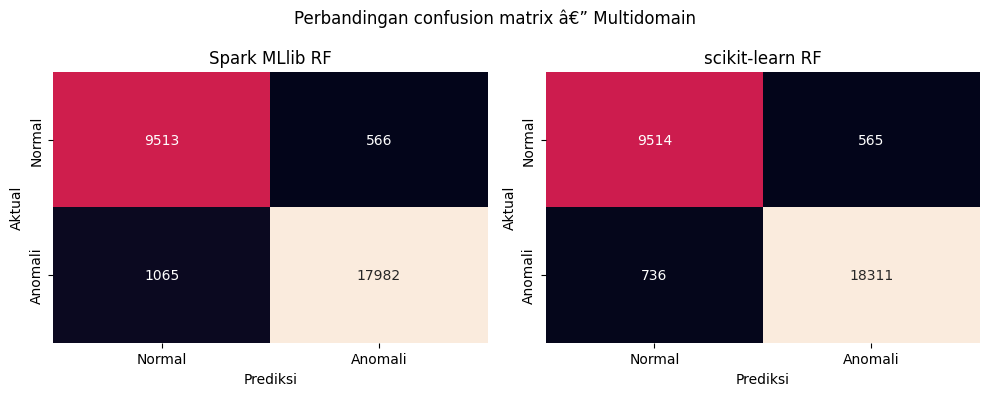

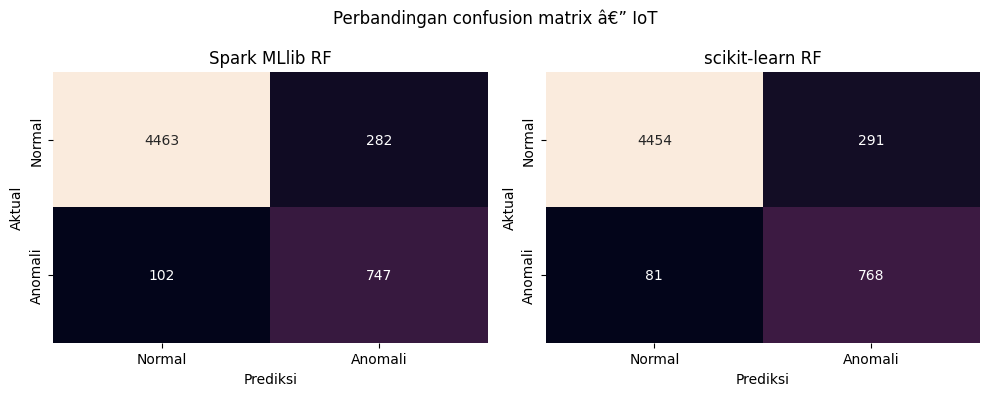

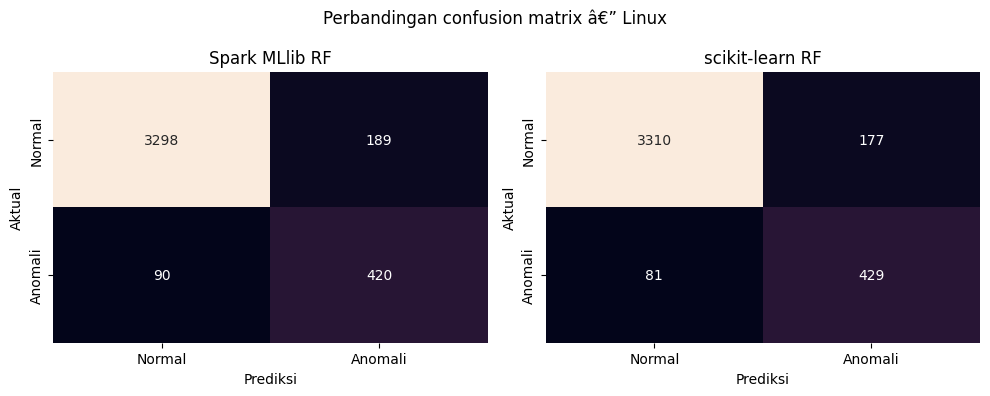

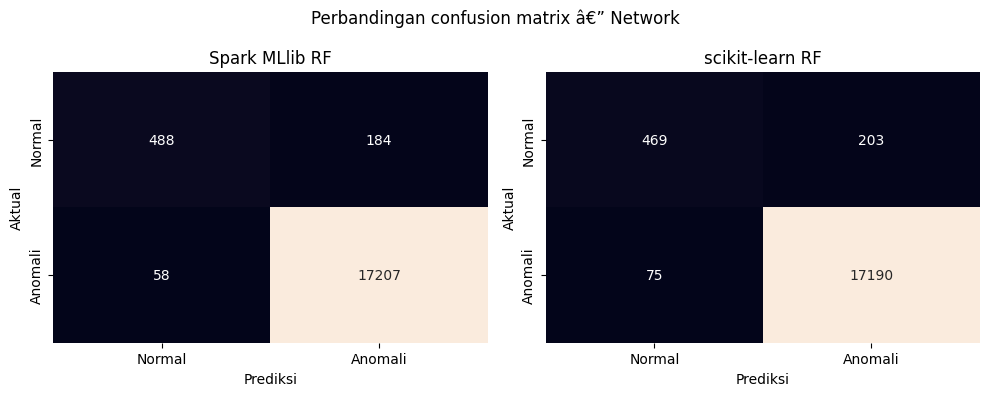

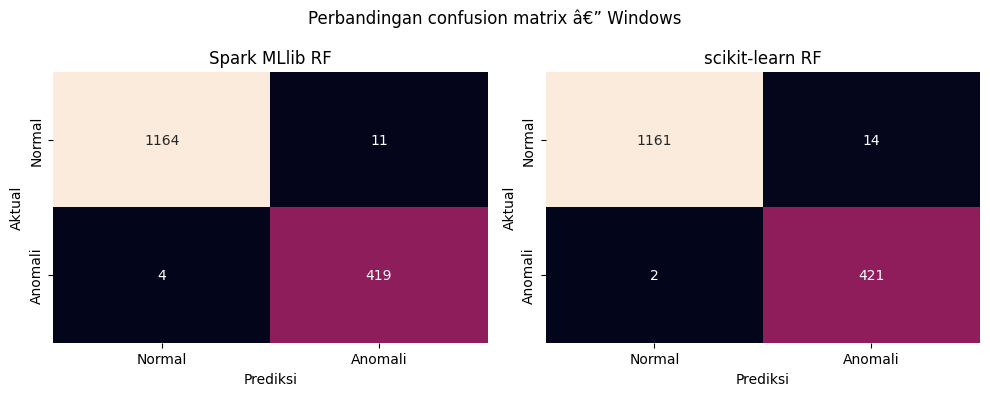

In [ ]:
for domain, result in domain_models.items():
    matrices = [("Spark MLlib RF", result["Confusion"]), ("scikit-learn RF", result["Sklearn_Confusion"])]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, (title, matrix) in zip(axes, matrices):
        sns.heatmap(np.asarray(matrix, dtype=int), annot=True, fmt="d", cbar=False,
                    xticklabels=["Normal", "Anomali"], yticklabels=["Normal", "Anomali"], ax=ax)
        ax.set_title(title)
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Aktual")
    fig.suptitle(f"Perbandingan confusion matrix â€” {domain}")
    plt.tight_layout()
    plt.savefig(f"confusion_matrix_comparison_{domain.lower()}.png", dpi=150)
    plt.show()

In [ ]:
anomaly_summary = []
for domain, result in domain_models.items():
    anomaly_summary.extend([
        {"Domain": domain, "Framework": "Spark MLlib â€” K-Means distance",
         "Normal": result["Normal_Count"], "Anomali": result["Anomaly_Count"]},
        {"Domain": domain, "Framework": "scikit-learn â€” Isolation Forest",
         "Normal": result["Sklearn_Normal_Count"], "Anomali": result["Sklearn_Anomaly_Count"]}
    ])
anomaly_summary_df = pd.DataFrame(anomaly_summary)
display(anomaly_summary_df)

,Domain,Framework,Normal,Anomali
0,Multidomain,Spark MLlib â€” K-Means distance,0,29126
1,Multidomain,scikit-learn â€” Isolation Forest,0,29126
2,IoT,Spark MLlib â€” K-Means distance,316,5278
3,IoT,scikit-learn â€” Isolation Forest,392,5202
4,Linux,Spark MLlib â€” K-Means distance,2468,1529
5,Linux,scikit-learn â€” Isolation Forest,2983,1014
6,Network,Spark MLlib â€” K-Means distance,0,17937
7,Network,scikit-learn â€” Isolation Forest,1,17936
8,Windows,Spark MLlib â€” K-Means distance,0,1598
9,Windows,scikit-learn â€” Isolation Forest,537,1061


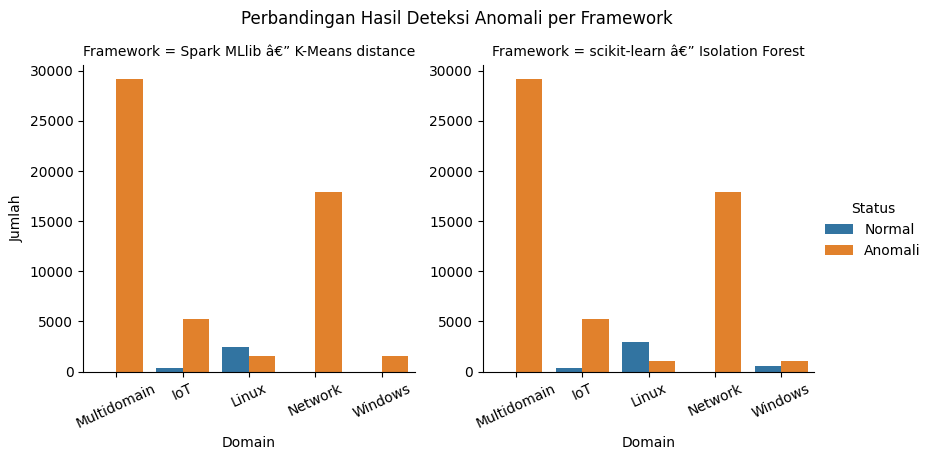

In [ ]:
plot_data = anomaly_summary_df.melt(
    id_vars=["Domain", "Framework"], value_vars=["Normal", "Anomali"],
    var_name="Status", value_name="Jumlah"
)
comparison_plot = sns.catplot(
    data=plot_data, x="Domain", y="Jumlah", hue="Status", col="Framework",
    kind="bar", height=4, aspect=1.05, sharey=False
)
comparison_plot.set_xticklabels(rotation=25)
comparison_plot.fig.suptitle("Perbandingan Hasil Deteksi Anomali per Framework", y=1.05)
comparison_plot.savefig("anomaly_detection_framework_comparison.png", dpi=150)
plt.show()

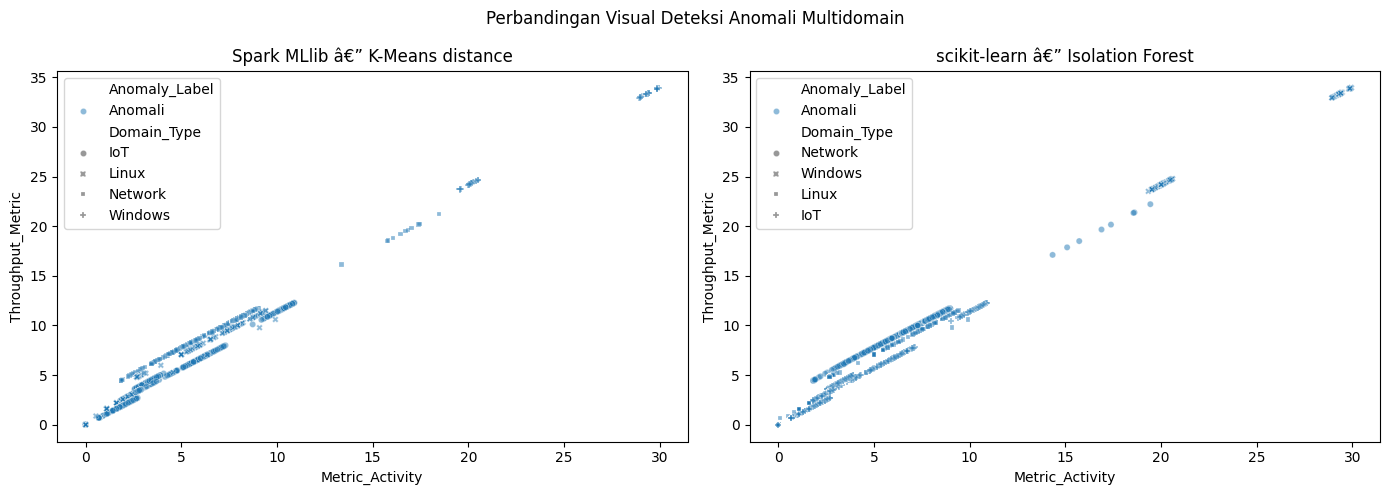

In [ ]:
if "Multidomain" in domain_models:
    multi_result = domain_models["Multidomain"]
    spark_plot = multi_result["plot_data"].copy()
    sklearn_plot = multi_result["sklearn_plot_data"].copy()
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    if not spark_plot.empty:
        spark_plot["Anomaly_Label"] = np.where(spark_plot["anomaly_prediction"] == 1, "Anomali", "Normal")
        sns.scatterplot(data=spark_plot, x="Metric_Activity", y="Throughput_Metric",
                        hue="Anomaly_Label", style="Domain_Type", alpha=0.5, s=20, ax=axes[0])
    axes[0].set_title("Spark MLlib â€” K-Means distance")
    if not sklearn_plot.empty:
        sklearn_plot["Anomaly_Label"] = np.where(sklearn_plot["IF_Anomaly"] == 1, "Anomali", "Normal")
        style_col = "Domain_Type" if "Domain_Type" in sklearn_plot.columns else None
        sns.scatterplot(data=sklearn_plot, x="Metric_Activity", y="Throughput_Metric",
                        hue="Anomaly_Label", style=style_col, alpha=0.5, s=20, ax=axes[1])
    axes[1].set_title("scikit-learn â€” Isolation Forest")
    fig.suptitle("Perbandingan Visual Deteksi Anomali Multidomain")
    plt.tight_layout()
    plt.savefig("anomaly_detection_multidomain_comparison.png", dpi=150)
    plt.show()
else:
    print("Grafik multidomain dilewati: model belum tersedia.")

In [ ]:
conf = spark.sparkContext._jsc.hadoopConfiguration()
fs = spark.sparkContext._gateway.jvm.org.apache.hadoop.fs.FileSystem.get(conf)

print("Hadoop FileSystem Class :", fs.getClass().getName())
print("Hadoop URI Scheme       :", fs.getScheme())
print("Hadoop Working Directory:", str(fs.getWorkingDirectory()))
print("Hadoop Home Directory   :", str(fs.getHomeDirectory()))

Hadoop FileSystem Class : org.apache.hadoop.hdfs.web.WebHdfsFileSystem
Hadoop URI Scheme       : webhdfs
Hadoop Working Directory: webhdfs://localhost:9870/user/jase0
Hadoop Home Directory   : webhdfs://localhost:9870/user/jase0


In [ ]:
import json
from pathlib import Path

models_dir = Path.cwd() / "models"
models_dir.mkdir(parents=True, exist_ok=True)

export_df = df_clustered.select(
    "Record_ID", "Domain_Type", "System_Region", "Device_Type",
    "Source_File", "Target_Label", "Target_Type", "cluster"
)
if HDFS_ENABLED:
    hdfs_output_path = f"{HDFS_NAMENODE.rstrip('/')}/{HDFS_OUTPUT_DIR.strip('/')}/clustered_parquet"
    export_df.write.mode("overwrite").parquet(hdfs_output_path)
    print(f"Parquet terdistribusi tersimpan di HDFS: {hdfs_output_path}")
else:
    output_file = Path(os.getenv("LOCAL_PARQUET_OUTPUT", "hadoop_clustered_output.parquet"))
    export_df.write.mode("overwrite").parquet(str(output_file))
    print(f"Parquet lokal tersimpan: {output_file.resolve()}")

domains = sorted([
    row["Domain_Type"]
    for row in df_clustered
        .select("Domain_Type")
        .distinct()
        .collect()
])

metadata = {
    "features": feature_cols,
    "domain_features": domain_feature_cols,
    "domain_evaluation_scope": "new-source generalization; separate source_model_evaluation.csv reports chronological within-source monitoring",
    "random_state": MODEL_RANDOM_STATE,
    "test_size": MODEL_TEST_SIZE,
    "n_estimators": MODEL_N_ESTIMATORS,
    "primary_classifier_mllib": "pyspark.ml.classification.RandomForestClassifier",
    "comparison_classifier_sklearn": "sklearn.ensemble.RandomForestClassifier",
    "comparison_anomaly_sklearn": "sklearn.ensemble.IsolationForest",
    "clustering": "pyspark.ml.clustering.KMeans",
    "anomaly_method": "K-Means squared distance; threshold calibrated on train labels to maximize F1 (per domain)",
    "anomaly_quantile": MODEL_ANOMALY_QUANTILE,
    "threshold_calibration": "per-domain: kmeans threshold = argmax F1 on train distances; IF threshold = argmax F1 on train decision scores; RF threshold = argmax F1 on OOF probabilities (scikit-learn) or stratified holdout-train probabilities (MLlib), 0.5 included as candidate",
    "frameworks_compared": ["Spark MLlib", "scikit-learn"],
    "comparison_sample_limit": 100000,
    "comparison_split": "same held-out source-file rows or random-row fallback from the shared Spark sample",
    "split_selection": "source-file holdout: first arrangement (seeded) with both classes on each side and |train prevalence - test prevalence| <= 0.05; otherwise the arrangement with the smallest prevalence gap; random-row fallback when no valid arrangement exists",
    "mapreduce_note": "Spark RDD map/reduce-style aggregation; not Hadoop MapReduce",
    "domains": domains,
    "files": file_summary
}

with open(
    models_dir / "model_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=2,
        default=str
    )

file_summary_df.to_csv(
    "dataset_file_summary.csv",
    index=False
)

evaluation_df.to_csv(
    "model_summary.csv",
    index=False
)

print()
print("=" * 60)
print("FILE MODEL")
print("=" * 60)
print(f"Model directory: {models_dir.resolve()}")
print(f"Metadata        : {(models_dir / 'model_metadata.json').resolve()}")
print(f"Dataset summary : {Path('dataset_file_summary.csv').resolve()}")
print(f"Model summary   : {Path('model_summary.csv').resolve()}")

print()
print("Model:")
for path in sorted(models_dir.glob("*_mllib")):
    print(f"  {path.name}/ (Spark MLlib model artifacts)")
for path in sorted(models_dir.glob("*_sklearn_*.pkl")):
    print(f"  {path.name} (scikit-learn model)")


Parquet terdistribusi tersimpan di HDFS: webhdfs://localhost:9870/analytics/iot-multidomain/clustered_parquet

FILE MODEL
Model directory: C:\Users\jase0\Documents\Binus\S2\Big_Data_Large_Scale_MultiDomain\model\models
Metadata        : C:\Users\jase0\Documents\Binus\S2\Big_Data_Large_Scale_MultiDomain\model\models\model_metadata.json
Dataset summary : C:\Users\jase0\Documents\Binus\S2\Big_Data_Large_Scale_MultiDomain\model\dataset_file_summary.csv
Model summary   : C:\Users\jase0\Documents\Binus\S2\Big_Data_Large_Scale_MultiDomain\model\model_summary.csv

Model:
  iot_mllib/ (Spark MLlib model artifacts)
  linux_mllib/ (Spark MLlib model artifacts)
  multidomain_mllib/ (Spark MLlib model artifacts)
  network_mllib/ (Spark MLlib model artifacts)
  windows_mllib/ (Spark MLlib model artifacts)
  iot_sklearn_attack_type.pkl (scikit-learn model)
  iot_sklearn_isolation_forest.pkl (scikit-learn model)
  iot_sklearn_kmeans.pkl (scikit-learn model)
  iot_sklearn_random_forest.pkl (scikit-lear

In [ ]:
print("Cakupan dataset:")
display(
    file_summary_df.groupby("domain")
    .agg(files=("file", "nunique"), rows=("rows_used", "sum"))
    .reset_index()
)

print("Evaluasi model:")
display(
    evaluation_df[
        [
            "Domain",
            "Records",
            "Train",
            "Test",
            "Best_K",
            "Train_Silhouette",
            "Test_Silhouette",
            "Accuracy",
            "Precision",
            "Recall",
            "F1"
        ]
    ].sort_values("Domain")
)

print("Semua domain yang tersedia:")
print(sorted(pdf_ml["Domain_Type"].unique().tolist()))

Cakupan dataset:


,domain,files,rows
0,IoT,7,3606134
1,Linux,5,4855329
2,Network,23,21340803
3,Windows,2,64342


Evaluasi model:


,Domain,Records,Train,Test,Best_K,Train_Silhouette,Test_Silhouette,Accuracy,Precision,Recall,F1
1,IoT,28000,22406,5594,2,NaN,NaN,0.931355,0.725948,0.879859,0.795527
2,Linux,20000,16003,3997,2,NaN,NaN,0.930198,0.689655,0.823529,0.750670
0,Multidomain,145786,116660,29126,2,NaN,NaN,0.944002,0.969485,0.944086,0.956617
3,Network,89786,71849,17937,2,NaN,NaN,0.986508,0.989420,0.996641,0.993017
4,Windows,8000,6402,1598,2,NaN,NaN,0.990613,0.974419,0.990544,0.982415


Semua domain yang tersedia:
['IoT', 'Linux', 'Network', 'Windows']
